# Selective Open-World Intrusion Detection on CICIDS2017

This notebook is configured for:

```text
/kaggle/input/datasets/furqanrustam118/cicids2017/cicids2017_cleaned.csv
```

Target column:

```text
Attack Type
```

The experiment:

1. Loads the 684 MB CSV safely in chunks.
2. Completely excludes one attack family from initial training.
3. Trains an embedding model on benign traffic and known attacks.
4. Detects the excluded attack as unknown.
5. Clusters rejected unknown samples.
6. Calculates an adaptation-worthiness score.
7. Adds the new attack using 1, 5, 10, or 20 confirmed examples.
8. Uses two improved lightweight adaptation methods:
   - guarded prototype adaptation;
   - balanced classifier-head adaptation with replay and knowledge distillation.
9. Repeats every few-shot experiment across several random trials.
10. Measures new-class recall and precision, known-class retention, forgetting,
    adaptation time, and updated-parameter ratio.

## Scientific wording

For CICIDS2017, describe the experiment as:

> **Held-out attack-family evaluation under an open-world protocol.**

Do not claim that this dataset alone proves true zero-day detection.

In [1]:
# ============================================================
# CELL 1: OPTIONAL INSTALLATION
# ============================================================
# Kaggle normally has these packages already.
# Uncomment only if an import error occurs.

# !pip install -q numpy pandas scikit-learn matplotlib torch joblib

In [2]:
# ============================================================
# CELL 2: IMPORTS AND REPRODUCIBILITY
# ============================================================

import gc
import json
import time
import random
import warnings
from pathlib import Path
from collections import defaultdict

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch device:", DEVICE)

PyTorch device: cuda


In [3]:
# ============================================================
# CELL 3: EXACT DATASET AND EXPERIMENT CONFIGURATION
# ============================================================

DATA_PATH = Path(
    "/kaggle/input/datasets/furqanrustam118/"
    "cicids2017/cicids2017_cleaned.csv"
)

LABEL_COLUMN = "Attack Type"

# Attack family completely excluded from initial training.
UNKNOWN_ATTACK = "DDoS"

# First run:
#   QUICK_MODE = False
#   MAX_ROWS_PER_CLASS = 30000
#
# Larger experiment:
#   QUICK_MODE = False
#   MAX_ROWS_PER_CLASS = 100000
#
# Full CSV:
#   MAX_ROWS_PER_CLASS = None
# Full loading may exceed Kaggle RAM.
QUICK_MODE = False
MAX_ROWS_PER_CLASS = 30000 if QUICK_MODE else 100000

CSV_CHUNK_SIZE = 100000
MIN_CLASS_SAMPLES = 300

TEST_SIZE = 0.20
VALIDATION_SIZE_FROM_REMAINING = 0.20

HIDDEN_DIMS = (128, 64)
EMBEDDING_DIM = 32
DROPOUT = 0.20
BATCH_SIZE = 1024
EPOCHS = 12 if QUICK_MODE else 25
PATIENCE = 4
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

KNOWN_DISTANCE_QUANTILE = 0.95

# ------------------------------------------------------------
# UPDATED ADAPTATION SETTINGS
# ------------------------------------------------------------

ADAPTATION_SHOTS = (1, 5, 10, 20)

# Number of independent selections of few-shot examples.
# Increase to 20 for the final paper if runtime permits.
ADAPTATION_TRIALS = 20

# Old examples retained per known class during head adaptation.
REPLAY_PER_CLASS = 100

# Improved head-adaptation optimization.
HEAD_ADAPTATION_EPOCHS = 50
HEAD_ADAPTATION_LR = 1e-3

# Knowledge distillation protects the old classifier behavior.
DISTILLATION_WEIGHT = 1.0
DISTILLATION_TEMPERATURE = 2.0

# Guarded prototype adaptation permits at most approximately 1%
# of known validation samples to switch to the new class.
ALLOWED_KNOWN_INTERFERENCE = 0.01

OUTPUT_DIR = Path(
    "/kaggle/working/open_world_cicids2017_results"
)
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Dataset:", DATA_PATH)
print("Target column:", LABEL_COLUMN)
print("Held-out attack:", UNKNOWN_ATTACK)
print("Quick mode:", QUICK_MODE)
print("Per-class maximum:", MAX_ROWS_PER_CLASS)
print("Adaptation trials:", ADAPTATION_TRIALS)

Dataset: /kaggle/input/datasets/furqanrustam118/cicids2017/cicids2017_cleaned.csv
Target column: Attack Type
Held-out attack: DDoS
Quick mode: False
Per-class maximum: 100000
Adaptation trials: 20


In [4]:
# ============================================================
# CELL 4: VERIFY THE EXACT KAGGLE FILE
# ============================================================

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset file was not found:\n{DATA_PATH}\n\n"
        "Confirm that the dataset is attached to this Kaggle notebook."
    )

file_size_mb = DATA_PATH.stat().st_size / (1024 ** 2)

print("Dataset file found.")
print(f"File size: {file_size_mb:.2f} MB")

Dataset file found.
File size: 684.02 MB


In [5]:
# ============================================================
# CELL 5: NORMALIZE CICIDS2017 ATTACK LABELS
# ============================================================

def normalize_attack_label(value):
    text = str(value).strip()

    replacements = {
        "\ufffd": "-",
        "\u2013": "-",
        "\u2014": "-",
        "\u2212": "-",
    }

    for old_character, new_character in replacements.items():
        text = text.replace(
            old_character,
            new_character,
        )

    text = " ".join(text.split())
    lower_text = text.lower()

    canonical = {
        "benign": "BENIGN",
        "normal": "BENIGN",
        "ddos": "DDoS",
        "portscan": "PortScan",
        "bot": "Bot",
        "infiltration": "Infiltration",
        "ftp-patator": "FTP-Patator",
        "ssh-patator": "SSH-Patator",
        "dos hulk": "DoS Hulk",
        "dos goldeneye": "DoS GoldenEye",
        "dos slowloris": "DoS slowloris",
        "dos slowhttptest": "DoS Slowhttptest",
        "heartbleed": "Heartbleed",
        "web attack - brute force": "Web Attack - Brute Force",
        "web attack - xss": "Web Attack - XSS",
        "web attack - sql injection": "Web Attack - Sql Injection",
    }

    return canonical.get(
        lower_text,
        text,
    )

In [6]:
# ============================================================
# CELL 6: MEMORY-SAFE CHUNKED CSV LOADER
# ============================================================

def load_balanced_cicids2017(
    csv_path,
    label_column,
    chunk_size=100000,
    max_rows_per_class=30000,
    seed=SEED,
):
    '''
    Read the large CSV in chunks.

    When max_rows_per_class is not None, at most that many rows are retained
    from each class. This makes the first Kaggle run practical and prevents
    the BENIGN class from dominating memory.

    For the final paper, report the sampling limit used.
    '''
    collected_parts = defaultdict(list)
    retained_counts = defaultdict(int)

    reader = pd.read_csv(
        csv_path,
        chunksize=chunk_size,
        low_memory=False,
    )

    for chunk_number, chunk in enumerate(
        reader,
        start=1,
    ):
        chunk.columns = [
            str(column).strip()
            for column in chunk.columns
        ]

        if label_column not in chunk.columns:
            raise KeyError(
                f"Target column '{label_column}' was not found. "
                f"Columns are: {chunk.columns.tolist()}"
            )

        chunk[label_column] = (
            chunk[label_column]
            .map(normalize_attack_label)
        )

        chunk = chunk.replace(
            [np.inf, -np.inf],
            np.nan,
        )

        if max_rows_per_class is None:
            collected_parts["__all__"].append(
                chunk
            )
        else:
            for class_name, class_group in (
                chunk.groupby(label_column)
            ):
                remaining = (
                    max_rows_per_class
                    - retained_counts[class_name]
                )

                if remaining <= 0:
                    continue

                if len(class_group) > remaining:
                    class_group = class_group.sample(
                        n=remaining,
                        random_state=(
                            seed + chunk_number
                        ),
                    )

                collected_parts[class_name].append(
                    class_group
                )

                retained_counts[class_name] += len(
                    class_group
                )

        if chunk_number % 5 == 0:
            print(
                f"Processed {chunk_number} chunks"
            )

        del chunk
        gc.collect()

    if max_rows_per_class is None:
        final_frame = pd.concat(
            collected_parts["__all__"],
            ignore_index=True,
            sort=False,
        )
    else:
        class_frames = []

        for class_name in sorted(
            collected_parts.keys()
        ):
            if class_name == "__all__":
                continue

            if collected_parts[class_name]:
                class_frames.append(
                    pd.concat(
                        collected_parts[class_name],
                        ignore_index=True,
                        sort=False,
                    )
                )

        final_frame = pd.concat(
            class_frames,
            ignore_index=True,
            sort=False,
        )

    return final_frame


df = load_balanced_cicids2017(
    DATA_PATH,
    LABEL_COLUMN,
    chunk_size=CSV_CHUNK_SIZE,
    max_rows_per_class=MAX_ROWS_PER_CLASS,
)

print("\nLoaded dataset shape:", df.shape)

class_distribution = (
    df[LABEL_COLUMN]
    .value_counts()
    .rename_axis("Attack Type")
    .reset_index(name="Count")
)

display(class_distribution)

Processed 5 chunks
Processed 10 chunks
Processed 15 chunks
Processed 20 chunks
Processed 25 chunks

Loaded dataset shape: (403935, 53)


,Attack Type,Count
0,DDoS,100000
1,Normal Traffic,100000
2,DoS,100000
3,Port Scanning,90694
4,Brute Force,9150
5,Web Attacks,2143
6,Bots,1948


## Data-integrity audit and duplicate-safe evaluation

In [7]:
# ============================================================
# DATA-INTEGRITY AUDIT: MUST RUN BEFORE ANY TRAIN/TEST SPLIT
# ============================================================
# Exact duplicates can otherwise cross row-level splits and inflate performance.
rows_before_deduplication = len(df)
duplicate_columns = list(df.columns)
duplicate_mask = df.duplicated(subset=duplicate_columns, keep="first")
exact_duplicate_count = int(duplicate_mask.sum())
exact_duplicate_rate = exact_duplicate_count / max(1, rows_before_deduplication)

duplicate_audit_df = pd.DataFrame([{
    "rows_before": rows_before_deduplication,
    "exact_duplicates": exact_duplicate_count,
    "duplicate_rate": exact_duplicate_rate,
    "rows_after": rows_before_deduplication - exact_duplicate_count,
}])
display(duplicate_audit_df)

# All downstream splits now use the de-duplicated frame.
df = df.loc[~duplicate_mask].reset_index(drop=True)
assert not df.duplicated(subset=duplicate_columns).any()
print(f"Duplicate-safe dataset: {len(df):,} rows retained.")

,rows_before,exact_duplicates,duplicate_rate,rows_after
0,403935,6,0.000015,403929


Duplicate-safe dataset: 403,929 rows retained.


In [8]:
# ============================================================
# CELL 7: VALIDATE LABELS AND REMOVE VERY SMALL CLASSES
# ============================================================

class_counts = df[
    LABEL_COLUMN
].value_counts()

small_classes = class_counts[
    class_counts < MIN_CLASS_SAMPLES
].index.tolist()

if small_classes:
    print(
        "Removing classes with fewer than "
        f"{MIN_CLASS_SAMPLES} samples:"
    )
    print(small_classes)

    df = df[
        ~df[LABEL_COLUMN].isin(
            small_classes
        )
    ].reset_index(drop=True)

available_classes = sorted(
    df[LABEL_COLUMN].unique().tolist()
)

print("\nAvailable classes:")
for class_name in available_classes:
    print(" -", class_name)

if UNKNOWN_ATTACK not in available_classes:
    raise ValueError(
        f"UNKNOWN_ATTACK='{UNKNOWN_ATTACK}' does not match "
        f"the available classes:\n{available_classes}"
    )


Available classes:
 - Bots
 - Brute Force
 - DDoS
 - DoS
 - Normal Traffic
 - Port Scanning
 - Web Attacks


In [9]:
# ============================================================
# CELL 8: AUTOMATIC FEATURE SELECTION AND CLEANING
# ============================================================

# Your cleaned CSV contains numerical flow features and the target column.
NON_FEATURE_COLUMNS = {
    LABEL_COLUMN,
}

feature_columns = [
    column
    for column in df.columns
    if column not in NON_FEATURE_COLUMNS
]

# Convert all candidate features to numeric.
for column in feature_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

# Remove all-missing and constant columns.
all_missing_columns = [
    column
    for column in feature_columns
    if df[column].isna().all()
]

constant_columns = [
    column
    for column in feature_columns
    if df[column].nunique(
        dropna=True
    ) <= 1
]

columns_to_remove = sorted(
    set(
        all_missing_columns
        + constant_columns
    )
)

if columns_to_remove:
    print("Removing unusable columns:")
    print(columns_to_remove)

    df = df.drop(
        columns=columns_to_remove
    )

feature_columns = [
    column
    for column in df.columns
    if column != LABEL_COLUMN
]

print("Number of numerical features:", len(feature_columns))
print("Final dataset shape:", df.shape)

print("\nFeature names:")
for index, column in enumerate(
    feature_columns,
    start=1,
):
    print(f"{index:02d}. {column}")

Number of numerical features: 52
Final dataset shape: (403929, 53)

Feature names:
01. Destination Port
02. Flow Duration
03. Total Fwd Packets
04. Total Length of Fwd Packets
05. Fwd Packet Length Max
06. Fwd Packet Length Min
07. Fwd Packet Length Mean
08. Fwd Packet Length Std
09. Bwd Packet Length Max
10. Bwd Packet Length Min
11. Bwd Packet Length Mean
12. Bwd Packet Length Std
13. Flow Bytes/s
14. Flow Packets/s
15. Flow IAT Mean
16. Flow IAT Std
17. Flow IAT Max
18. Flow IAT Min
19. Fwd IAT Total
20. Fwd IAT Mean
21. Fwd IAT Std
22. Fwd IAT Max
23. Fwd IAT Min
24. Bwd IAT Total
25. Bwd IAT Mean
26. Bwd IAT Std
27. Bwd IAT Max
28. Bwd IAT Min
29. Fwd Header Length
30. Bwd Header Length
31. Fwd Packets/s
32. Bwd Packets/s
33. Min Packet Length
34. Max Packet Length
35. Packet Length Mean
36. Packet Length Std
37. Packet Length Variance
38. FIN Flag Count
39. PSH Flag Count
40. ACK Flag Count
41. Average Packet Size
42. Subflow Fwd Bytes
43. Init_Win_bytes_forward
44. Init_Win_byte

In [10]:
# ============================================================
# CELL 9: OPEN-WORLD TRAIN/VALIDATION/TEST SPLIT
# ============================================================

known_df = df[
    df[LABEL_COLUMN] != UNKNOWN_ATTACK
].copy()

unknown_df = df[
    df[LABEL_COLUMN] == UNKNOWN_ATTACK
].copy()

known_train_val_df, known_test_df = (
    train_test_split(
        known_df,
        test_size=TEST_SIZE,
        stratify=known_df[LABEL_COLUMN],
        random_state=SEED,
    )
)

known_train_df, known_val_df = (
    train_test_split(
        known_train_val_df,
        test_size=VALIDATION_SIZE_FROM_REMAINING,
        stratify=known_train_val_df[
            LABEL_COLUMN
        ],
        random_state=SEED,
    )
)

unknown_adapt_df, unknown_test_df = (
    train_test_split(
        unknown_df,
        test_size=0.70,
        random_state=SEED,
    )
)

known_train_df = (
    known_train_df.reset_index(drop=True)
)
known_val_df = (
    known_val_df.reset_index(drop=True)
)
known_test_df = (
    known_test_df.reset_index(drop=True)
)
unknown_adapt_df = (
    unknown_adapt_df.reset_index(drop=True)
)
unknown_test_df = (
    unknown_test_df.reset_index(drop=True)
)

assert UNKNOWN_ATTACK not in set(
    known_train_df[LABEL_COLUMN]
)

print("Known training:", known_train_df.shape)
print("Known validation:", known_val_df.shape)
print("Known testing:", known_test_df.shape)
print("Unknown adaptation pool:", unknown_adapt_df.shape)
print("Unknown final testing:", unknown_test_df.shape)

Known training: (194514, 53)
Known validation: (48629, 53)
Known testing: (60786, 53)
Unknown adaptation pool: (30000, 53)
Unknown final testing: (70000, 53)


In [11]:
# ============================================================
# CELL 10: TRAINING-ONLY IMPUTATION AND STANDARDIZATION
# ============================================================

training_medians = (
    known_train_df[feature_columns]
    .median()
)

def prepare_features(frame):
    prepared = frame[
        feature_columns
    ].copy()

    prepared = prepared.replace(
        [np.inf, -np.inf],
        np.nan,
    )

    prepared = prepared.fillna(
        training_medians
    )

    prepared = prepared.fillna(0.0)

    return prepared.astype(
        np.float32
    )


X_train_raw = prepare_features(
    known_train_df
)
X_val_raw = prepare_features(
    known_val_df
)
X_known_test_raw = prepare_features(
    known_test_df
)
X_unknown_adapt_raw = prepare_features(
    unknown_adapt_df
)
X_unknown_test_raw = prepare_features(
    unknown_test_df
)

scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = scaler.transform(
    X_val_raw
).astype(np.float32)

X_known_test = scaler.transform(
    X_known_test_raw
).astype(np.float32)

X_unknown_adapt = scaler.transform(
    X_unknown_adapt_raw
).astype(np.float32)

X_unknown_test = scaler.transform(
    X_unknown_test_raw
).astype(np.float32)

print("Training feature matrix:", X_train.shape)

Training feature matrix: (194514, 52)


In [12]:
# ============================================================
# CELL 11: ENCODE KNOWN CLASS LABELS
# ============================================================

known_classes = sorted(
    known_train_df[
        LABEL_COLUMN
    ].unique().tolist()
)

class_to_index = {
    class_name: class_index
    for class_index, class_name
    in enumerate(known_classes)
}

index_to_class = {
    class_index: class_name
    for class_name, class_index
    in class_to_index.items()
}

def encode_known_labels(series):
    encoded = series.map(
        class_to_index
    )

    if encoded.isna().any():
        missing_classes = (
            series[encoded.isna()]
            .unique()
            .tolist()
        )

        raise ValueError(
            "Classes absent from training appeared later: "
            f"{missing_classes}"
        )

    return encoded.astype(int).to_numpy()


y_train = encode_known_labels(
    known_train_df[LABEL_COLUMN]
)
y_val = encode_known_labels(
    known_val_df[LABEL_COLUMN]
)
y_known_test = encode_known_labels(
    known_test_df[LABEL_COLUMN]
)

print("Known-class mapping:")
for class_name, class_index in (
    class_to_index.items()
):
    print(class_index, class_name)

Known-class mapping:
0 Bots
1 Brute Force
2 DoS
3 Normal Traffic
4 Port Scanning
5 Web Attacks


In [13]:
# ============================================================
# CELL 12: CLASS WEIGHTS AND DATA LOADERS
# ============================================================

class_counts = np.bincount(
    y_train,
    minlength=len(known_classes),
)

class_weights = (
    len(y_train)
    / (
        len(known_classes)
        * class_counts
    )
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

def make_loader(
    X,
    y,
    batch_size,
    shuffle,
):
    dataset = TensorDataset(
        torch.tensor(
            X,
            dtype=torch.float32,
        ),
        torch.tensor(
            y,
            dtype=torch.long,
        ),
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=False,
        num_workers=0,
    )


train_loader = make_loader(
    X_train,
    y_train,
    BATCH_SIZE,
    True,
)

val_loader = make_loader(
    X_val,
    y_val,
    BATCH_SIZE,
    False,
)

print("Class weights:")
for index, weight in enumerate(
    class_weights
):
    print(
        index_to_class[index],
        float(weight),
    )

Class weights:
Bots 25.99759422614274
Brute Force 5.536031420765028
DoS 0.506546875
Normal Traffic 0.5065785361585099
Port Scanning 0.5585245675694301
Web Attacks 23.64624361779723


In [14]:
# ============================================================
# CELL 13: NEURAL EMBEDDING MODEL
# ============================================================

class OpenWorldMLP(nn.Module):
    def __init__(
        self,
        input_dim,
        num_classes,
        hidden_dims=(128, 64),
        embedding_dim=32,
        dropout=0.20,
    ):
        super().__init__()

        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(
                    previous_dim,
                    hidden_dim,
                ),
                nn.BatchNorm1d(
                    hidden_dim
                ),
                nn.ReLU(),
                nn.Dropout(
                    dropout
                ),
            ])

            previous_dim = hidden_dim

        self.backbone = nn.Sequential(
            *layers
        )

        self.embedding_layer = nn.Linear(
            previous_dim,
            embedding_dim,
        )

        self.classifier = nn.Linear(
            embedding_dim,
            num_classes,
        )

    def encode(self, features):
        hidden = self.backbone(
            features
        )

        embedding = self.embedding_layer(
            hidden
        )

        return F.normalize(
            embedding,
            p=2,
            dim=1,
        )

    def forward(self, features):
        embedding = self.encode(
            features
        )

        logits = self.classifier(
            embedding
        )

        return logits, embedding


model = OpenWorldMLP(
    input_dim=X_train.shape[1],
    num_classes=len(
        known_classes
    ),
    hidden_dims=HIDDEN_DIMS,
    embedding_dim=EMBEDDING_DIM,
    dropout=DROPOUT,
).to(DEVICE)

print(model)

OpenWorldMLP(
  (backbone): Sequential(
    (0): Linear(in_features=52, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
  )
  (embedding_layer): Linear(in_features=64, out_features=32, bias=True)
  (classifier): Linear(in_features=32, out_features=6, bias=True)
)


In [15]:
# ============================================================
# CELL 14: TRAIN INITIAL KNOWN-CLASS MODEL
# ============================================================

def evaluate_known_model(
    network,
    loader,
):
    network.eval()

    total_loss = 0.0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for features, targets in loader:
            features = features.to(
                DEVICE
            )
            targets = targets.to(
                DEVICE
            )

            logits, _ = network(
                features
            )

            loss = F.cross_entropy(
                logits,
                targets,
                weight=class_weights_tensor,
            )

            total_loss += (
                loss.item()
                * len(features)
            )

            true_labels.extend(
                targets.cpu().numpy()
            )

            predicted_labels.extend(
                logits
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

    average_loss = (
        total_loss
        / len(loader.dataset)
    )

    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        average="macro",
    )

    return average_loss, macro_f1


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": [],
}

best_state = None
best_val_loss = float("inf")
stale_epochs = 0

for epoch in range(
    1,
    EPOCHS + 1,
):
    model.train()

    running_loss = 0.0

    for features, targets in (
        train_loader
    ):
        features = features.to(
            DEVICE
        )
        targets = targets.to(
            DEVICE
        )

        optimizer.zero_grad()

        logits, _ = model(
            features
        )

        loss = F.cross_entropy(
            logits,
            targets,
            weight=class_weights_tensor,
        )

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item()
            * len(features)
        )

    train_loss = (
        running_loss
        / len(train_loader.dataset)
    )

    val_loss, val_macro_f1 = (
        evaluate_known_model(
            model,
            val_loader,
        )
    )

    history["train_loss"].append(
        train_loss
    )
    history["val_loss"].append(
        val_loss
    )
    history["val_macro_f1"].append(
        val_macro_f1
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss={train_loss:.4f} | "
        f"val loss={val_loss:.4f} | "
        f"val macro-F1={val_macro_f1:.4f}"
    )

    if val_loss < (
        best_val_loss - 1e-4
    ):
        best_val_loss = val_loss

        best_state = {
            key: value
            .detach()
            .cpu()
            .clone()
            for key, value
            in model.state_dict().items()
        }

        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= PATIENCE:
        print("Early stopping.")
        break

if best_state is not None:
    model.load_state_dict(
        best_state
    )

Epoch 01 | train loss=1.1243 | val loss=0.7176 | val macro-F1=0.7458
Epoch 02 | train loss=0.5524 | val loss=0.3816 | val macro-F1=0.7831
Epoch 03 | train loss=0.3263 | val loss=0.2475 | val macro-F1=0.7969
Epoch 04 | train loss=0.2311 | val loss=0.1835 | val macro-F1=0.8154
Epoch 05 | train loss=0.1810 | val loss=0.1565 | val macro-F1=0.8090
Epoch 06 | train loss=0.1589 | val loss=0.1313 | val macro-F1=0.8038
Epoch 07 | train loss=0.1389 | val loss=0.1110 | val macro-F1=0.8246
Epoch 08 | train loss=0.1262 | val loss=0.1122 | val macro-F1=0.8138
Epoch 09 | train loss=0.1180 | val loss=0.0997 | val macro-F1=0.8229
Epoch 10 | train loss=0.1112 | val loss=0.0919 | val macro-F1=0.8289
Epoch 11 | train loss=0.1036 | val loss=0.0837 | val macro-F1=0.8285
Epoch 12 | train loss=0.1004 | val loss=0.0808 | val macro-F1=0.8256
Epoch 13 | train loss=0.0955 | val loss=0.0774 | val macro-F1=0.8347
Epoch 14 | train loss=0.0965 | val loss=0.0784 | val macro-F1=0.8232
Epoch 15 | train loss=0.0930 | val

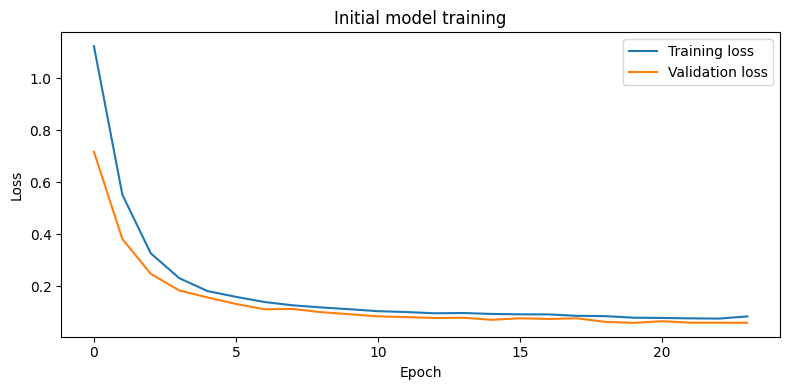

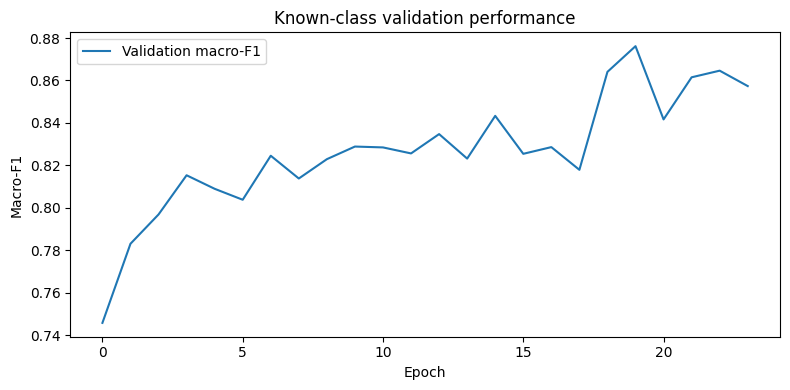

In [16]:
# ============================================================
# CELL 15: TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 4))
plt.plot(
    history["train_loss"],
    label="Training loss",
)
plt.plot(
    history["val_loss"],
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Initial model training")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    history["val_macro_f1"],
    label="Validation macro-F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Known-class validation performance")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 16: EXTRACT EMBEDDINGS
# ============================================================

def extract_embeddings(
    network,
    X,
    batch_size=4096,
):
    network.eval()

    dataset = TensorDataset(
        torch.tensor(
            X,
            dtype=torch.float32,
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    collected_embeddings = []

    with torch.no_grad():
        for (features,) in loader:
            features = features.to(
                DEVICE
            )

            embeddings = network.encode(
                features
            )

            collected_embeddings.append(
                embeddings
                .cpu()
                .numpy()
            )

    return np.concatenate(
        collected_embeddings,
        axis=0,
    )


Z_train = extract_embeddings(
    model,
    X_train,
)
Z_val = extract_embeddings(
    model,
    X_val,
)
Z_known_test = extract_embeddings(
    model,
    X_known_test,
)
Z_unknown_adapt = extract_embeddings(
    model,
    X_unknown_adapt,
)
Z_unknown_test = extract_embeddings(
    model,
    X_unknown_test,
)

print("Training embeddings:", Z_train.shape)

Training embeddings: (194514, 32)


In [18]:
# ============================================================
# CELL 17: PROTOTYPES AND DISTANCE FUNCTIONS
# ============================================================

def compute_prototypes(
    embeddings,
    labels,
):
    prototypes = {}

    for class_index in sorted(
        np.unique(labels)
    ):
        prototype = embeddings[
            labels == class_index
        ].mean(axis=0)

        prototype = prototype / (
            np.linalg.norm(
                prototype
            )
            + 1e-12
        )

        prototypes[
            int(class_index)
        ] = prototype.astype(
            np.float32
        )

    return prototypes


def prototype_distance_matrix(
    embeddings,
    prototype_dictionary,
):
    ordered_classes = sorted(
        prototype_dictionary.keys()
    )

    prototype_matrix = np.stack([
        prototype_dictionary[
            class_index
        ]
        for class_index
        in ordered_classes
    ])

    distances = np.linalg.norm(
        embeddings[:, None, :]
        - prototype_matrix[None, :, :],
        axis=2,
    )

    return (
        distances,
        ordered_classes,
    )


def nearest_prototype_predictions(
    embeddings,
    prototype_dictionary,
):
    distances, ordered_classes = (
        prototype_distance_matrix(
            embeddings,
            prototype_dictionary,
        )
    )

    nearest_positions = (
        distances.argmin(axis=1)
    )

    predictions = np.array([
        ordered_classes[position]
        for position
        in nearest_positions
    ])

    minimum_distances = (
        distances.min(axis=1)
    )

    return (
        predictions,
        minimum_distances,
    )


prototypes = compute_prototypes(
    Z_train,
    y_train,
)

print("Known prototypes:", len(prototypes))

Known prototypes: 6


In [19]:
# ============================================================
# CELL 18: CALIBRATE UNKNOWN-REJECTION THRESHOLD
# ============================================================

val_predictions, val_distances = (
    nearest_prototype_predictions(
        Z_val,
        prototypes,
    )
)

OPEN_SET_THRESHOLD = float(
    np.quantile(
        val_distances,
        KNOWN_DISTANCE_QUANTILE,
    )
)

validation_false_unknown_rate = float(
    np.mean(
        val_distances
        > OPEN_SET_THRESHOLD
    )
)

print(
    "Open-set distance threshold:",
    OPEN_SET_THRESHOLD,
)

print(
    "Validation false-unknown rate:",
    validation_false_unknown_rate,
)

Open-set distance threshold: 0.3534960448741913
Validation false-unknown rate: 0.04999074626251825


In [20]:
# ============================================================
# CELL 19: PRE-ADAPTATION OPEN-WORLD EVALUATION
# ============================================================

UNKNOWN_INDEX = len(
    known_classes
)

known_predictions, known_distances = (
    nearest_prototype_predictions(
        Z_known_test,
        prototypes,
    )
)

unknown_predictions_as_known, unknown_distances = (
    nearest_prototype_predictions(
        Z_unknown_test,
        prototypes,
    )
)

known_open_predictions = np.where(
    known_distances
    > OPEN_SET_THRESHOLD,
    UNKNOWN_INDEX,
    known_predictions,
)

unknown_open_predictions = np.where(
    unknown_distances
    > OPEN_SET_THRESHOLD,
    UNKNOWN_INDEX,
    unknown_predictions_as_known,
)

binary_true = np.concatenate([
    np.zeros(
        len(known_distances),
        dtype=int,
    ),
    np.ones(
        len(unknown_distances),
        dtype=int,
    ),
])

binary_score = np.concatenate([
    known_distances,
    unknown_distances,
])

unknown_auroc = roc_auc_score(
    binary_true,
    binary_score,
)

unknown_auprc = average_precision_score(
    binary_true,
    binary_score,
)

unknown_recall = float(
    np.mean(
        unknown_open_predictions
        == UNKNOWN_INDEX
    )
)

false_unknown_rate = float(
    np.mean(
        known_open_predictions
        == UNKNOWN_INDEX
    )
)

open_true = np.concatenate([
    y_known_test,
    np.full(
        len(unknown_test_df),
        UNKNOWN_INDEX,
        dtype=int,
    ),
])

open_predictions = np.concatenate([
    known_open_predictions,
    unknown_open_predictions,
])

open_macro_f1 = f1_score(
    open_true,
    open_predictions,
    average="macro",
)

pre_adaptation_metrics = {
    "held_out_attack": (
        UNKNOWN_ATTACK
    ),
    "unknown_auroc": float(
        unknown_auroc
    ),
    "unknown_auprc": float(
        unknown_auprc
    ),
    "unknown_recall": (
        unknown_recall
    ),
    "false_unknown_rate": (
        false_unknown_rate
    ),
    "open_set_macro_f1": float(
        open_macro_f1
    ),
    "distance_threshold": (
        OPEN_SET_THRESHOLD
    ),
}

print(
    json.dumps(
        pre_adaptation_metrics,
        indent=2,
    )
)

{
  "held_out_attack": "DDoS",
  "unknown_auroc": 0.8885536528617962,
  "unknown_auprc": 0.8488235577524632,
  "unknown_recall": 0.29715714285714284,
  "false_unknown_rate": 0.05062020860066463,
  "open_set_macro_f1": 0.7029903596178864,
  "distance_threshold": 0.3534960448741913
}


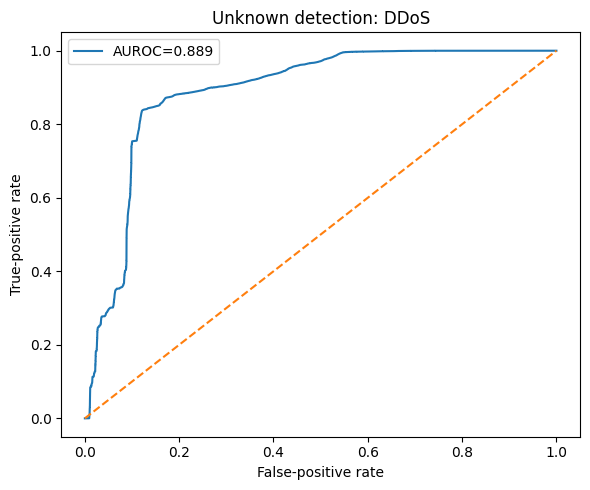

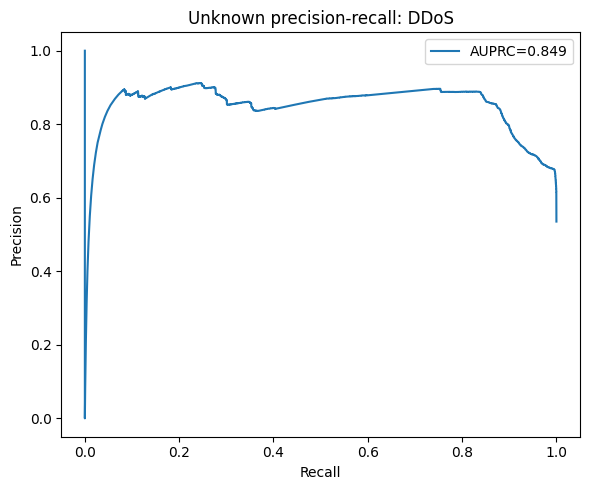

In [21]:
# ============================================================
# CELL 20: UNKNOWN-DETECTION CURVES
# ============================================================

false_positive_rate, true_positive_rate, _ = (
    roc_curve(
        binary_true,
        binary_score,
    )
)

plt.figure(figsize=(6, 5))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"AUROC={unknown_auroc:.3f}",
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title(
    f"Unknown detection: {UNKNOWN_ATTACK}"
)
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = (
    precision_recall_curve(
        binary_true,
        binary_score,
    )
)

plt.figure(figsize=(6, 5))
plt.plot(
    recall,
    precision,
    label=f"AUPRC={unknown_auprc:.3f}",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    f"Unknown precision-recall: {UNKNOWN_ATTACK}"
)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CELL 21: CLUSTER REJECTED UNKNOWN CANDIDATES
# ============================================================

_, unknown_adapt_distances = (
    nearest_prototype_predictions(
        Z_unknown_adapt,
        prototypes,
    )
)

rejected_mask = (
    unknown_adapt_distances
    > OPEN_SET_THRESHOLD
)

Z_rejected = Z_unknown_adapt[
    rejected_mask
]

rejected_novelty_scores = (
    unknown_adapt_distances[
        rejected_mask
    ]
)

print(
    "Unknown adaptation samples:",
    len(Z_unknown_adapt),
)

print(
    "Rejected as unknown:",
    len(Z_rejected),
)

def estimate_dbscan_eps(
    embeddings,
    min_samples=5,
):
    if len(embeddings) <= min_samples:
        return 0.3

    neighbors = NearestNeighbors(
        n_neighbors=min_samples
    )

    neighbors.fit(
        embeddings
    )

    distances, _ = neighbors.kneighbors(
        embeddings
    )

    return float(
        np.quantile(
            distances[:, -1],
            0.85,
        )
    )


DBSCAN_MIN_SAMPLES = 5

if len(Z_rejected) >= (
    DBSCAN_MIN_SAMPLES
):
    DBSCAN_EPS = estimate_dbscan_eps(
        Z_rejected,
        DBSCAN_MIN_SAMPLES,
    )

    cluster_ids = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=(
            DBSCAN_MIN_SAMPLES
        ),
    ).fit_predict(
        Z_rejected
    )
else:
    DBSCAN_EPS = None

    cluster_ids = np.full(
        len(Z_rejected),
        -1,
    )

print("DBSCAN eps:", DBSCAN_EPS)

print(
    pd.Series(
        cluster_ids
    )
    .value_counts()
    .sort_index()
)

Unknown adaptation samples: 30000
Rejected as unknown: 8988
DBSCAN eps: 0.0007813261763658373
-1     1275
 0     1463
 1     1024
 2      946
 3      594
 4      439
 5      200
 6     1240
 7      203
 8       48
 9       92
 10      13
 11     198
 12      13
 13     196
 14     148
 15      24
 16       5
 17     127
 18      62
 19      59
 20      52
 21      36
 22      25
 23       8
 24      11
 25      11
 26       9
 27       8
 28      42
 29      34
 30      25
 31      29
 32      21
 33      19
 34      10
 35      33
 36      48
 37      15
 38      17
 39      13
 40       6
 41      17
 42      17
 43      12
 44       8
 45      21
 46       6
 47       7
 48      10
 49      15
 50      10
 51      10
 52       5
 53       4
 54       5
Name: count, dtype: int64


In [23]:
# ============================================================
# CELL 22: ADAPTATION-WORTHINESS SCORE
# ============================================================

def min_max_scale(values):
    values = np.asarray(
        values,
        dtype=float,
    )

    if len(values) == 0:
        return values

    minimum = values.min()
    maximum = values.max()

    if maximum - minimum < 1e-12:
        return np.ones_like(
            values
        )

    return (
        (values - minimum)
        / (maximum - minimum)
    )


def calculate_cluster_worthiness(
    embeddings,
    novelty_scores,
    assigned_clusters,
    known_threshold,
):
    rows = []

    for cluster_id in sorted(
        np.unique(
            assigned_clusters
        )
    ):
        if cluster_id == -1:
            continue

        mask = (
            assigned_clusters
            == cluster_id
        )

        cluster_embeddings = (
            embeddings[mask]
        )

        cluster_novelty = (
            novelty_scores[mask]
        )

        centroid = (
            cluster_embeddings
            .mean(axis=0)
        )

        centroid = centroid / (
            np.linalg.norm(
                centroid
            )
            + 1e-12
        )

        mean_radius = np.linalg.norm(
            cluster_embeddings
            - centroid,
            axis=1,
        ).mean()

        rows.append({
            "cluster_id": int(
                cluster_id
            ),
            "support": int(
                mask.sum()
            ),
            "raw_novelty": max(
                0.0,
                float(
                    cluster_novelty.mean()
                    - known_threshold
                ),
            ),
            "compactness": float(
                1.0
                / (1.0 + mean_radius)
            ),
        })

    if not rows:
        return pd.DataFrame(
            columns=[
                "cluster_id",
                "support",
                "raw_novelty",
                "compactness",
                "worthiness_score",
            ]
        )

    result = pd.DataFrame(
        rows
    )

    result["novelty_norm"] = (
        min_max_scale(
            result[
                "raw_novelty"
            ].to_numpy()
        )
    )

    result["support_norm"] = (
        min_max_scale(
            result[
                "support"
            ].to_numpy()
        )
    )

    result["compactness_norm"] = (
        min_max_scale(
            result[
                "compactness"
            ].to_numpy()
        )
    )

    result["worthiness_score"] = (
        0.45
        * result["novelty_norm"]
        + 0.35
        * result["support_norm"]
        + 0.20
        * result[
            "compactness_norm"
        ]
    )

    return result.sort_values(
        "worthiness_score",
        ascending=False,
    ).reset_index(drop=True)


worthiness_df = (
    calculate_cluster_worthiness(
        Z_rejected,
        rejected_novelty_scores,
        cluster_ids,
        OPEN_SET_THRESHOLD,
    )
)

display(worthiness_df)

,cluster_id,support,raw_novelty,compactness,novelty_norm,support_norm,compactness_norm,worthiness_score
0,6,1240,0.476149,0.994579,0.923290,0.847156,0.227801,0.757545
1,1,1024,0.494239,0.994590,0.960145,0.699109,0.229462,0.722646
2,0,1463,0.285611,0.995354,0.535095,1.000000,0.342709,0.659334
3,31,29,0.513801,0.999111,1.000000,0.017135,0.899725,0.635942
4,10,13,0.480594,0.999633,0.932346,0.006169,0.977105,0.617136
5,53,4,0.464986,0.999788,0.900546,0.000000,1.000000,0.605246
6,41,17,0.472025,0.999313,0.914887,0.008910,0.929619,0.600741
7,33,19,0.475017,0.999190,0.920983,0.010281,0.911425,0.600326
8,25,11,0.469622,0.999373,0.909991,0.004798,0.938499,0.598875
9,8,48,0.465377,0.998563,0.901343,0.030158,0.818360,0.579831


In [24]:
# ============================================================
# CELL 23: FAIR PRE-ADAPTATION BASELINES
# ============================================================

# Prototype baseline: used for guarded prototype adaptation.
known_prototype_predictions_before, _ = (
    nearest_prototype_predictions(
        Z_known_test,
        prototypes,
    )
)

known_prototype_f1_before = f1_score(
    y_known_test,
    known_prototype_predictions_before,
    average="macro",
)

known_prototype_accuracy_before = accuracy_score(
    y_known_test,
    known_prototype_predictions_before,
)

# Neural-head baseline: used for classifier-head adaptation.
model.eval()

with torch.no_grad():
    known_head_logits_before = model.classifier(
        torch.tensor(
            Z_known_test,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

known_head_predictions_before = (
    known_head_logits_before
    .argmax(dim=1)
    .cpu()
    .numpy()
)

known_head_f1_before = f1_score(
    y_known_test,
    known_head_predictions_before,
    average="macro",
)

known_head_accuracy_before = accuracy_score(
    y_known_test,
    known_head_predictions_before,
)

print(
    "Prototype baseline macro-F1:",
    known_prototype_f1_before,
)
print(
    "Prototype baseline accuracy:",
    known_prototype_accuracy_before,
)
print(
    "Original neural-head macro-F1:",
    known_head_f1_before,
)
print(
    "Original neural-head accuracy:",
    known_head_accuracy_before,
)

Prototype baseline macro-F1: 0.8585404946883818
Prototype baseline accuracy: 0.9720823873918336
Original neural-head macro-F1: 0.8698254225646022
Original neural-head accuracy: 0.9747803770605074


In [25]:
# ============================================================
# CELL 24: GUARDED PROTOTYPE FEW-SHOT ADAPTATION
# ============================================================

def guarded_new_class_predictions(
    embeddings,
    old_prototypes,
    new_prototype,
    guard_threshold,
):
    '''
    Assign a sample to the newly learned class only when the new prototype is
    sufficiently closer than every existing prototype.

    advantage = nearest old distance - new-class distance

    A larger positive advantage favors the new class.
    '''
    old_predictions, old_distances = (
        nearest_prototype_predictions(
            embeddings,
            old_prototypes,
        )
    )

    new_distances = np.linalg.norm(
        embeddings
        - new_prototype[None, :],
        axis=1,
    )

    new_class_advantage = (
        old_distances
        - new_distances
    )

    final_predictions = (
        old_predictions.copy()
    )

    final_predictions[
        new_class_advantage
        > guard_threshold
    ] = UNKNOWN_INDEX

    return (
        final_predictions,
        new_class_advantage,
    )


def evaluate_guarded_prototype_adaptation(
    shots,
    seed,
    allowed_known_interference=0.01,
):
    '''
    Add one new-class prototype from a few confirmed samples.

    The guard threshold is calibrated using known validation samples only.
    This prevents the new prototype from attracting too many old-class
    examples.
    '''
    rng = np.random.default_rng(seed)

    selected_indices = rng.choice(
        len(Z_unknown_adapt),
        size=shots,
        replace=False,
    )

    confirmed_embeddings = (
        Z_unknown_adapt[
            selected_indices
        ]
    )

    new_prototype = (
        confirmed_embeddings
        .mean(axis=0)
    )

    new_prototype = (
        new_prototype
        / (
            np.linalg.norm(
                new_prototype
            )
            + 1e-12
        )
    )

    # Calibrate the guard using only known validation samples.
    _, validation_advantage = (
        guarded_new_class_predictions(
            Z_val,
            prototypes,
            new_prototype,
            guard_threshold=-np.inf,
        )
    )

    guard_threshold = float(
        np.quantile(
            validation_advantage,
            1.0
            - allowed_known_interference,
        )
    )

    start_time = time.perf_counter()

    known_after, _ = (
        guarded_new_class_predictions(
            Z_known_test,
            prototypes,
            new_prototype,
            guard_threshold,
        )
    )

    unknown_after, _ = (
        guarded_new_class_predictions(
            Z_unknown_test,
            prototypes,
            new_prototype,
            guard_threshold,
        )
    )

    adaptation_seconds = (
        time.perf_counter()
        - start_time
    )

    known_f1_after = f1_score(
        y_known_test,
        known_after,
        labels=list(range(len(known_classes))),
        average="macro",
        zero_division=0,
    )

    new_true_positive = int(
        np.sum(
            unknown_after
            == UNKNOWN_INDEX
        )
    )

    known_false_positive = int(
        np.sum(
            known_after
            == UNKNOWN_INDEX
        )
    )

    new_class_recall = (
        new_true_positive
        / max(1, len(unknown_after))
    )

    new_class_precision = (
        new_true_positive
        / max(
            1,
            new_true_positive
            + known_false_positive,
        )
    )

    false_new_class_rate = (
        known_false_positive
        / max(1, len(known_after))
    )

    return {
        "method": "guarded_prototype",
        "shots": int(shots),
        "trial_seed": int(seed),
        "guard_threshold": float(
            guard_threshold
        ),
        "known_macro_f1_before": float(
            known_prototype_f1_before
        ),
        "known_macro_f1_after": float(
            known_f1_after
        ),
        "new_class_recall": float(
            new_class_recall
        ),
        "new_class_precision": float(
            new_class_precision
        ),
        "false_new_class_rate": float(
            false_new_class_rate
        ),
        "average_forgetting": float(
            known_prototype_f1_before
            - known_f1_after
        ),
        "adaptation_seconds": float(
            adaptation_seconds
        ),
        "updated_parameter_ratio": 0.0,
    }


guarded_prototype_trial_results = []

for shots in ADAPTATION_SHOTS:
    for trial in range(
        ADAPTATION_TRIALS
    ):
        trial_seed = (
            2000
            + shots * 100
            + trial
        )

        result = (
            evaluate_guarded_prototype_adaptation(
                shots=shots,
                seed=trial_seed,
                allowed_known_interference=(
                    ALLOWED_KNOWN_INTERFERENCE
                ),
            )
        )

        guarded_prototype_trial_results.append(
            result
        )

guarded_prototype_trials_df = pd.DataFrame(
    guarded_prototype_trial_results
)

guarded_prototype_summary = (
    guarded_prototype_trials_df
    .groupby("shots")
    .agg(
        new_class_recall_mean=(
            "new_class_recall",
            "mean",
        ),
        new_class_recall_std=(
            "new_class_recall",
            "std",
        ),
        new_class_precision_mean=(
            "new_class_precision",
            "mean",
        ),
        new_class_precision_std=(
            "new_class_precision",
            "std",
        ),
        known_f1_after_mean=(
            "known_macro_f1_after",
            "mean",
        ),
        known_f1_after_std=(
            "known_macro_f1_after",
            "std",
        ),
        forgetting_mean=(
            "average_forgetting",
            "mean",
        ),
        forgetting_std=(
            "average_forgetting",
            "std",
        ),
        false_new_class_rate_mean=(
            "false_new_class_rate",
            "mean",
        ),
        adaptation_seconds_mean=(
            "adaptation_seconds",
            "mean",
        ),
    )
    .reset_index()
)

print("Guarded prototype summary:")
display(guarded_prototype_summary)

Guarded prototype summary:


,shots,new_class_recall_mean,new_class_recall_std,new_class_precision_mean,new_class_precision_std,known_f1_after_mean,known_f1_after_std,forgetting_mean,forgetting_std,false_new_class_rate_mean,adaptation_seconds_mean
0,1,0.233172,0.164839,0.924549,0.068228,0.856426,0.000534,0.002115,0.000534,0.010049,0.143545
1,5,0.174042,0.194051,0.690046,0.309907,0.858833,0.001618,-0.000293,0.001618,0.010054,0.142172
2,10,0.145871,0.119127,0.761295,0.309693,0.859299,0.001558,-0.000759,0.001558,0.010164,0.141287
3,20,0.147296,0.119475,0.771187,0.274818,0.859929,0.001059,-0.001389,0.001059,0.010064,0.140606


In [26]:
# ============================================================
# CELL 25: IMPROVED HEAD-ONLY ADAPTATION
# ============================================================

class ExpandedLinearHead(nn.Module):
    '''
    Classifier head containing all old classes plus one newly confirmed class.

    Old weights are copied exactly. The new-class weight is initialized from
    the mean embedding of confirmed new-attack examples.
    '''

    def __init__(
        self,
        old_head,
        embedding_dim,
        total_classes,
        new_class_prototype,
    ):
        super().__init__()

        self.linear = nn.Linear(
            embedding_dim,
            total_classes,
        )

        old_class_count = (
            old_head.out_features
        )

        with torch.no_grad():
            self.linear.weight[
                :old_class_count
            ].copy_(
                old_head.weight
            )

            self.linear.bias[
                :old_class_count
            ].copy_(
                old_head.bias
            )

            old_weight_norm = (
                old_head.weight
                .norm(dim=1)
                .mean()
            )

            normalized_prototype = (
                new_class_prototype
                / (
                    new_class_prototype.norm()
                    + 1e-12
                )
            )

            self.linear.weight[
                old_class_count
            ].copy_(
                normalized_prototype
                * old_weight_norm
            )

            self.linear.bias[
                old_class_count
            ].copy_(
                old_head.bias.mean()
            )

    def forward(
        self,
        embeddings,
    ):
        return self.linear(
            embeddings
        )


def build_balanced_replay_memory(
    embeddings,
    labels,
    per_class,
    seed,
):
    '''
    Select the same number of replay examples from every existing class.
    '''
    rng = np.random.default_rng(
        seed
    )

    replay_embeddings = []
    replay_labels = []

    for class_index in sorted(
        np.unique(labels)
    ):
        candidate_indices = np.where(
            labels == class_index
        )[0]

        selected_indices = rng.choice(
            candidate_indices,
            size=min(
                per_class,
                len(candidate_indices),
            ),
            replace=False,
        )

        replay_embeddings.append(
            embeddings[
                selected_indices
            ]
        )

        replay_labels.append(
            labels[
                selected_indices
            ]
        )

    return (
        np.concatenate(
            replay_embeddings,
            axis=0,
        ),
        np.concatenate(
            replay_labels,
            axis=0,
        ),
    )


def evaluate_improved_head_adaptation(
    shots,
    seed,
):
    '''
    Adapt only the classifier head.

    Improvements:
      1. Balanced replay from every old class.
      2. Oversampling of the few new-class examples.
      3. Small embedding-space augmentation.
      4. Prototype initialization for the new output neuron.
      5. Knowledge distillation to preserve old-class behavior.
      6. Frozen feature encoder.
    '''
    set_seed(seed)

    rng = np.random.default_rng(
        seed
    )

    selected_indices = rng.choice(
        len(Z_unknown_adapt),
        size=shots,
        replace=False,
    )

    confirmed_new_Z = (
        Z_unknown_adapt[
            selected_indices
        ]
    )

    replay_Z, replay_y = (
        build_balanced_replay_memory(
            Z_train,
            y_train,
            REPLAY_PER_CLASS,
            seed,
        )
    )

    # Match the new-class adaptation count to each old replay class.
    target_new_count = (
        REPLAY_PER_CLASS
    )

    repeat_count = int(
        np.ceil(
            target_new_count
            / len(confirmed_new_Z)
        )
    )

    balanced_new_Z = np.tile(
        confirmed_new_Z,
        (repeat_count, 1),
    )[:target_new_count]

    # Add small noise so oversampled examples are not exact duplicates.
    noise = rng.normal(
        loc=0.0,
        scale=0.01,
        size=balanced_new_Z.shape,
    ).astype(np.float32)

    balanced_new_Z = (
        balanced_new_Z
        + noise
    )

    balanced_new_Z = (
        balanced_new_Z
        / (
            np.linalg.norm(
                balanced_new_Z,
                axis=1,
                keepdims=True,
            )
            + 1e-12
        )
    ).astype(np.float32)

    balanced_new_y = np.full(
        target_new_count,
        UNKNOWN_INDEX,
        dtype=int,
    )

    adaptation_Z = np.concatenate([
        replay_Z,
        balanced_new_Z,
    ])

    adaptation_y = np.concatenate([
        replay_y,
        balanced_new_y,
    ])

    shuffled_indices = rng.permutation(
        len(adaptation_y)
    )

    adaptation_Z = adaptation_Z[
        shuffled_indices
    ]

    adaptation_y = adaptation_y[
        shuffled_indices
    ]

    adaptation_loader = make_loader(
        adaptation_Z,
        adaptation_y,
        batch_size=64,
        shuffle=True,
    )

    new_prototype = (
        confirmed_new_Z
        .mean(axis=0)
    )

    new_prototype = torch.tensor(
        new_prototype,
        dtype=torch.float32,
        device=DEVICE,
    )

    expanded_head = ExpandedLinearHead(
        old_head=model.classifier,
        embedding_dim=EMBEDDING_DIM,
        total_classes=(
            len(known_classes)
            + 1
        ),
        new_class_prototype=(
            new_prototype
        ),
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        expanded_head.parameters(),
        lr=HEAD_ADAPTATION_LR,
        weight_decay=1e-5,
    )

    old_class_count = len(
        known_classes
    )

    start_time = time.perf_counter()

    expanded_head.train()

    for epoch in range(
        HEAD_ADAPTATION_EPOCHS
    ):
        for embeddings, targets in (
            adaptation_loader
        ):
            embeddings = embeddings.to(
                DEVICE
            )

            targets = targets.to(
                DEVICE
            )

            optimizer.zero_grad()

            new_logits = expanded_head(
                embeddings
            )

            classification_loss = (
                F.cross_entropy(
                    new_logits,
                    targets,
                )
            )

            old_sample_mask = (
                targets
                < old_class_count
            )

            if old_sample_mask.any():
                old_embeddings = embeddings[
                    old_sample_mask
                ]

                with torch.no_grad():
                    original_logits = (
                        model.classifier(
                            old_embeddings
                        )
                    )

                adapted_old_logits = (
                    new_logits[
                        old_sample_mask,
                        :old_class_count,
                    ]
                )

                temperature = (
                    DISTILLATION_TEMPERATURE
                )

                distillation_loss = (
                    F.kl_div(
                        F.log_softmax(
                            adapted_old_logits
                            / temperature,
                            dim=1,
                        ),
                        F.softmax(
                            original_logits
                            / temperature,
                            dim=1,
                        ),
                        reduction="batchmean",
                    )
                    * (
                        temperature ** 2
                    )
                )
            else:
                distillation_loss = (
                    torch.tensor(
                        0.0,
                        device=DEVICE,
                    )
                )

            total_loss = (
                classification_loss
                + DISTILLATION_WEIGHT
                * distillation_loss
            )

            total_loss.backward()
            optimizer.step()

    adaptation_seconds = (
        time.perf_counter()
        - start_time
    )

    expanded_head.eval()

    with torch.no_grad():
        known_logits = expanded_head(
            torch.tensor(
                Z_known_test,
                dtype=torch.float32,
                device=DEVICE,
            )
        )

        unknown_logits = expanded_head(
            torch.tensor(
                Z_unknown_test,
                dtype=torch.float32,
                device=DEVICE,
            )
        )

    known_after = (
        known_logits
        .argmax(dim=1)
        .cpu()
        .numpy()
    )

    unknown_after = (
        unknown_logits
        .argmax(dim=1)
        .cpu()
        .numpy()
    )

    known_f1_after = f1_score(
        y_known_test,
        known_after,
        labels=list(range(len(known_classes))),
        average="macro",
        zero_division=0,
    )

    new_true_positive = int(
        np.sum(
            unknown_after
            == UNKNOWN_INDEX
        )
    )

    known_false_positive = int(
        np.sum(
            known_after
            == UNKNOWN_INDEX
        )
    )

    new_class_recall = (
        new_true_positive
        / max(1, len(unknown_after))
    )

    new_class_precision = (
        new_true_positive
        / max(
            1,
            new_true_positive
            + known_false_positive,
        )
    )

    false_new_class_rate = (
        known_false_positive
        / max(1, len(known_after))
    )

    total_model_parameters = sum(
        parameter.numel()
        for parameter
        in model.parameters()
    )

    updated_parameters = sum(
        parameter.numel()
        for parameter
        in expanded_head.parameters()
    )

    return {
        "method": (
            "improved_head_with_replay"
        ),
        "shots": int(shots),
        "trial_seed": int(seed),
        "known_macro_f1_before": float(
            known_head_f1_before
        ),
        "known_macro_f1_after": float(
            known_f1_after
        ),
        "new_class_recall": float(
            new_class_recall
        ),
        "new_class_precision": float(
            new_class_precision
        ),
        "false_new_class_rate": float(
            false_new_class_rate
        ),
        "average_forgetting": float(
            known_head_f1_before
            - known_f1_after
        ),
        "adaptation_seconds": float(
            adaptation_seconds
        ),
        "updated_parameter_ratio": float(
            updated_parameters
            / total_model_parameters
        ),
    }


improved_head_trial_results = []

for shots in ADAPTATION_SHOTS:
    for trial in range(
        ADAPTATION_TRIALS
    ):
        trial_seed = (
            1000
            + shots * 100
            + trial
        )

        result = (
            evaluate_improved_head_adaptation(
                shots=shots,
                seed=trial_seed,
            )
        )

        improved_head_trial_results.append(
            result
        )

        print(
            f"Head adaptation completed: "
            f"shots={shots}, trial={trial + 1}/"
            f"{ADAPTATION_TRIALS}"
        )

improved_head_trials_df = pd.DataFrame(
    improved_head_trial_results
)

improved_head_summary = (
    improved_head_trials_df
    .groupby("shots")
    .agg(
        new_class_recall_mean=(
            "new_class_recall",
            "mean",
        ),
        new_class_recall_std=(
            "new_class_recall",
            "std",
        ),
        new_class_precision_mean=(
            "new_class_precision",
            "mean",
        ),
        new_class_precision_std=(
            "new_class_precision",
            "std",
        ),
        known_f1_after_mean=(
            "known_macro_f1_after",
            "mean",
        ),
        known_f1_after_std=(
            "known_macro_f1_after",
            "std",
        ),
        forgetting_mean=(
            "average_forgetting",
            "mean",
        ),
        forgetting_std=(
            "average_forgetting",
            "std",
        ),
        false_new_class_rate_mean=(
            "false_new_class_rate",
            "mean",
        ),
        adaptation_seconds_mean=(
            "adaptation_seconds",
            "mean",
        ),
        updated_parameter_ratio_mean=(
            "updated_parameter_ratio",
            "mean",
        ),
    )
    .reset_index()
)

print("Improved classifier-head summary:")
display(improved_head_summary)

Head adaptation completed: shots=1, trial=1/20
Head adaptation completed: shots=1, trial=2/20
Head adaptation completed: shots=1, trial=3/20
Head adaptation completed: shots=1, trial=4/20
Head adaptation completed: shots=1, trial=5/20
Head adaptation completed: shots=1, trial=6/20
Head adaptation completed: shots=1, trial=7/20
Head adaptation completed: shots=1, trial=8/20
Head adaptation completed: shots=1, trial=9/20
Head adaptation completed: shots=1, trial=10/20
Head adaptation completed: shots=1, trial=11/20
Head adaptation completed: shots=1, trial=12/20
Head adaptation completed: shots=1, trial=13/20
Head adaptation completed: shots=1, trial=14/20
Head adaptation completed: shots=1, trial=15/20
Head adaptation completed: shots=1, trial=16/20
Head adaptation completed: shots=1, trial=17/20
Head adaptation completed: shots=1, trial=18/20
Head adaptation completed: shots=1, trial=19/20
Head adaptation completed: shots=1, trial=20/20
Head adaptation completed: shots=5, trial=1/20
He

,shots,new_class_recall_mean,new_class_recall_std,new_class_precision_mean,new_class_precision_std,known_f1_after_mean,known_f1_after_std,forgetting_mean,forgetting_std,false_new_class_rate_mean,adaptation_seconds_mean,updated_parameter_ratio_mean
0,1,0.254606,0.123481,0.888509,0.128442,0.863589,0.008299,0.006237,0.008299,0.027533,1.295692,0.013049
1,5,0.243854,0.092989,0.884580,0.089438,0.865356,0.001509,0.004469,0.001509,0.028428,1.270262,0.013049
2,10,0.255378,0.073115,0.900612,0.052907,0.866196,0.001149,0.003630,0.001149,0.028474,1.277437,0.013049
3,20,0.293375,0.059412,0.918380,0.040248,0.865236,0.001164,0.004590,0.001164,0.027938,1.306290,0.013049


,method,shots,new_class_recall_mean,new_class_recall_std,new_class_precision_mean,new_class_precision_std,known_f1_after_mean,known_f1_after_std,forgetting_mean,forgetting_std,false_new_class_rate_mean,adaptation_seconds_mean,updated_parameter_ratio_mean
0,guarded_prototype,1,0.233172,0.164839,0.924549,0.068228,0.856426,0.000534,0.002115,0.000534,0.010049,0.143545,0.000000
1,guarded_prototype,5,0.174042,0.194051,0.690046,0.309907,0.858833,0.001618,-0.000293,0.001618,0.010054,0.142172,0.000000
2,guarded_prototype,10,0.145871,0.119127,0.761295,0.309693,0.859299,0.001558,-0.000759,0.001558,0.010164,0.141287,0.000000
3,guarded_prototype,20,0.147296,0.119475,0.771187,0.274818,0.859929,0.001059,-0.001389,0.001059,0.010064,0.140606,0.000000
4,improved_head_with_replay,1,0.254606,0.123481,0.888509,0.128442,0.863589,0.008299,0.006237,0.008299,0.027533,1.295692,0.013049
5,improved_head_with_replay,5,0.243854,0.092989,0.884580,0.089438,0.865356,0.001509,0.004469,0.001509,0.028428,1.270262,0.013049
6,improved_head_with_replay,10,0.255378,0.073115,0.900612,0.052907,0.866196,0.001149,0.003630,0.001149,0.028474,1.277437,0.013049
7,improved_head_with_replay,20,0.293375,0.059412,0.918380,0.040248,0.865236,0.001164,0.004590,0.001164,0.027938,1.306290,0.013049


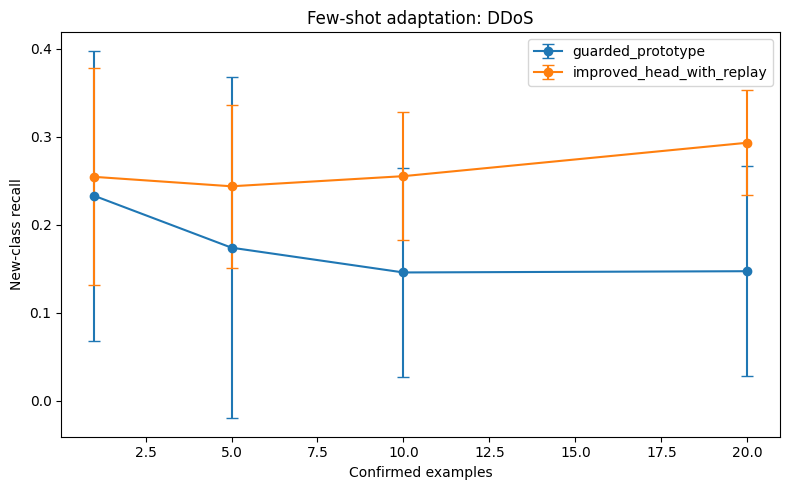

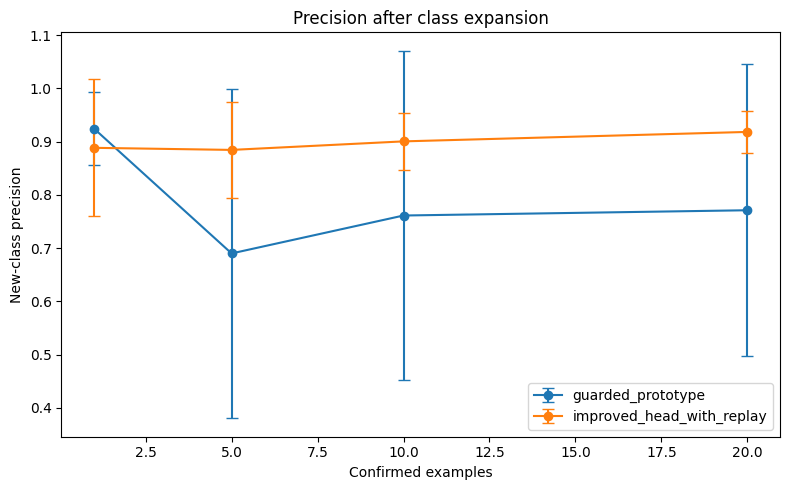

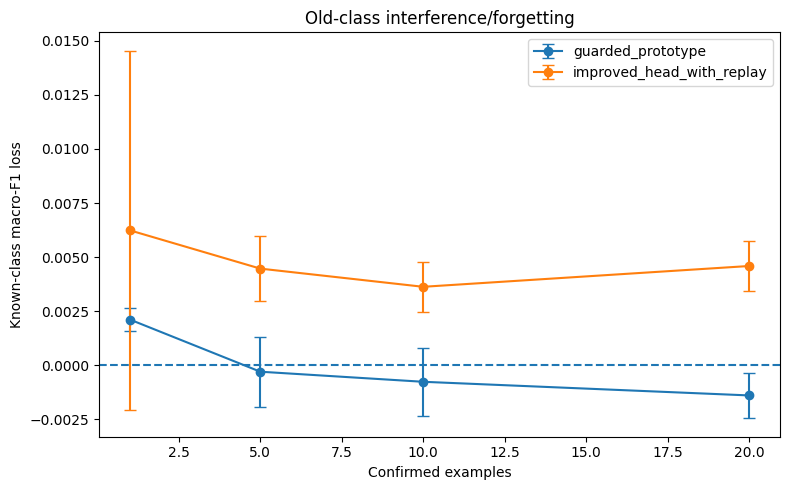

In [27]:
# ============================================================
# CELL 26: COMPARE UPDATED ADAPTATION METHODS
# ============================================================

all_adaptation_trials = pd.concat(
    [
        guarded_prototype_trials_df,
        improved_head_trials_df,
    ],
    ignore_index=True,
)

adaptation_summary = (
    all_adaptation_trials
    .groupby(
        [
            "method",
            "shots",
        ]
    )
    .agg(
        new_class_recall_mean=(
            "new_class_recall",
            "mean",
        ),
        new_class_recall_std=(
            "new_class_recall",
            "std",
        ),
        new_class_precision_mean=(
            "new_class_precision",
            "mean",
        ),
        new_class_precision_std=(
            "new_class_precision",
            "std",
        ),
        known_f1_after_mean=(
            "known_macro_f1_after",
            "mean",
        ),
        known_f1_after_std=(
            "known_macro_f1_after",
            "std",
        ),
        forgetting_mean=(
            "average_forgetting",
            "mean",
        ),
        forgetting_std=(
            "average_forgetting",
            "std",
        ),
        false_new_class_rate_mean=(
            "false_new_class_rate",
            "mean",
        ),
        adaptation_seconds_mean=(
            "adaptation_seconds",
            "mean",
        ),
        updated_parameter_ratio_mean=(
            "updated_parameter_ratio",
            "mean",
        ),
    )
    .reset_index()
)

display(adaptation_summary)

# New-class recall.
plt.figure(figsize=(8, 5))

for method, group in (
    adaptation_summary
    .groupby("method")
):
    group = group.sort_values(
        "shots"
    )

    plt.errorbar(
        group["shots"],
        group[
            "new_class_recall_mean"
        ],
        yerr=group[
            "new_class_recall_std"
        ],
        marker="o",
        capsize=4,
        label=method,
    )

plt.xlabel(
    "Confirmed examples"
)
plt.ylabel(
    "New-class recall"
)
plt.title(
    f"Few-shot adaptation: {UNKNOWN_ATTACK}"
)
plt.legend()
plt.tight_layout()
plt.show()

# New-class precision.
plt.figure(figsize=(8, 5))

for method, group in (
    adaptation_summary
    .groupby("method")
):
    group = group.sort_values(
        "shots"
    )

    plt.errorbar(
        group["shots"],
        group[
            "new_class_precision_mean"
        ],
        yerr=group[
            "new_class_precision_std"
        ],
        marker="o",
        capsize=4,
        label=method,
    )

plt.xlabel(
    "Confirmed examples"
)
plt.ylabel(
    "New-class precision"
)
plt.title(
    "Precision after class expansion"
)
plt.legend()
plt.tight_layout()
plt.show()

# Known-class forgetting.
plt.figure(figsize=(8, 5))

for method, group in (
    adaptation_summary
    .groupby("method")
):
    group = group.sort_values(
        "shots"
    )

    plt.errorbar(
        group["shots"],
        group[
            "forgetting_mean"
        ],
        yerr=group[
            "forgetting_std"
        ],
        marker="o",
        capsize=4,
        label=method,
    )

plt.axhline(
    0,
    linestyle="--",
)

plt.xlabel(
    "Confirmed examples"
)
plt.ylabel(
    "Known-class macro-F1 loss"
)
plt.title(
    "Old-class interference/forgetting"
)
plt.legend()
plt.tight_layout()
plt.show()

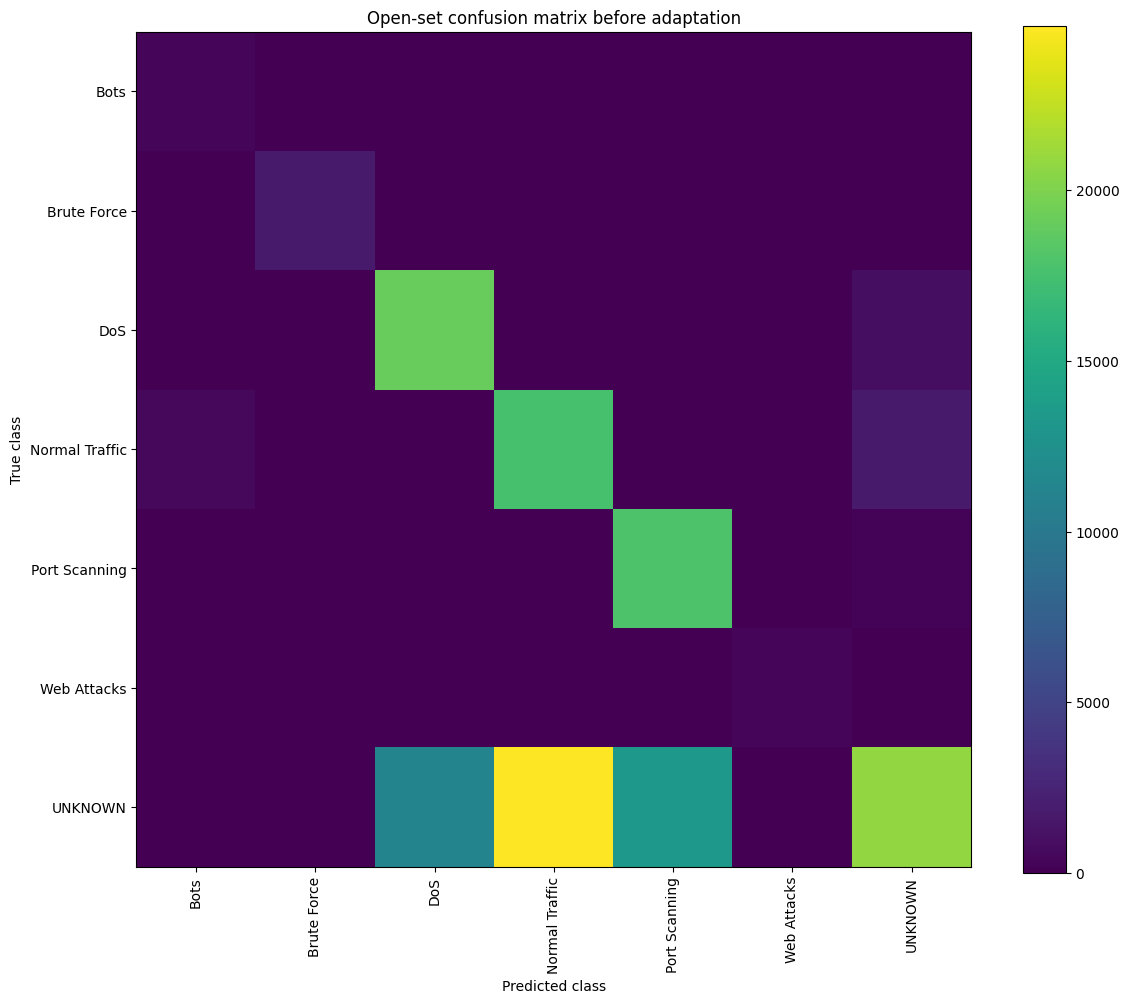

In [28]:
# ============================================================
# CELL 27: OPEN-SET CONFUSION MATRIX
# ============================================================

display_names = (
    known_classes
    + ["UNKNOWN"]
)

matrix = confusion_matrix(
    open_true,
    open_predictions,
    labels=list(
        range(
            len(display_names)
        )
    ),
)

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    matrix
)

plt.title(
    "Open-set confusion matrix "
    "before adaptation"
)

plt.xlabel(
    "Predicted class"
)

plt.ylabel(
    "True class"
)

plt.xticks(
    range(
        len(display_names)
    ),
    display_names,
    rotation=90,
)

plt.yticks(
    range(
        len(display_names)
    ),
    display_names,
)

plt.colorbar()
plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# CELL 28: SAVE ALL RESULTS
# ============================================================

with open(
    OUTPUT_DIR
    / "pre_adaptation_metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        pre_adaptation_metrics,
        file,
        indent=2,
    )

all_adaptation_trials.to_csv(
    OUTPUT_DIR
    / "adaptation_trial_results.csv",
    index=False,
)

adaptation_summary.to_csv(
    OUTPUT_DIR
    / "adaptation_summary.csv",
    index=False,
)

guarded_prototype_summary.to_csv(
    OUTPUT_DIR
    / "guarded_prototype_summary.csv",
    index=False,
)

improved_head_summary.to_csv(
    OUTPUT_DIR
    / "improved_head_summary.csv",
    index=False,
)

worthiness_df.to_csv(
    OUTPUT_DIR
    / "cluster_worthiness.csv",
    index=False,
)

class_distribution.to_csv(
    OUTPUT_DIR
    / "loaded_class_distribution.csv",
    index=False,
)

joblib.dump(
    scaler,
    OUTPUT_DIR
    / "feature_scaler.joblib",
)

torch.save(
    model.state_dict(),
    OUTPUT_DIR
    / "initial_known_model.pt",
)

np.savez(
    OUTPUT_DIR
    / "known_prototypes.npz",
    **{
        str(class_index): prototype
        for class_index, prototype
        in prototypes.items()
    },
)

with open(
    OUTPUT_DIR
    / "experiment_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "data_path": str(
                DATA_PATH
            ),
            "label_column": (
                LABEL_COLUMN
            ),
            "unknown_attack": (
                UNKNOWN_ATTACK
            ),
            "seed": SEED,
            "quick_mode": (
                QUICK_MODE
            ),
            "max_rows_per_class": (
                MAX_ROWS_PER_CLASS
            ),
            "minimum_class_samples": (
                MIN_CLASS_SAMPLES
            ),
            "feature_count": len(
                feature_columns
            ),
            "known_classes": (
                known_classes
            ),
            "adaptation_trials": (
                ADAPTATION_TRIALS
            ),
            "replay_per_class": (
                REPLAY_PER_CLASS
            ),
            "head_adaptation_epochs": (
                HEAD_ADAPTATION_EPOCHS
            ),
            "distillation_weight": (
                DISTILLATION_WEIGHT
            ),
            "distillation_temperature": (
                DISTILLATION_TEMPERATURE
            ),
            "allowed_known_interference": (
                ALLOWED_KNOWN_INTERFERENCE
            ),
        },
        file,
        indent=2,
    )

print("Results saved to:")
print(OUTPUT_DIR)

print("\nSaved files:")
for result_file in sorted(
    OUTPUT_DIR.iterdir()
):
    print(
        result_file.name
    )

Results saved to:
/kaggle/working/open_world_cicids2017_results

Saved files:
adaptation_summary.csv
adaptation_trial_results.csv
cluster_worthiness.csv
experiment_configuration.json
feature_scaler.joblib
guarded_prototype_summary.csv
improved_head_summary.csv
initial_known_model.pt
known_prototypes.npz
loaded_class_distribution.csv
pre_adaptation_metrics.json


# Next experiments for the paper

Repeat the notebook by changing only:

```python
UNKNOWN_ATTACK = "DDoS"
```

Possible larger held-out classes include:

```python
UNKNOWN_ATTACK = "Port Scanning"
UNKNOWN_ATTACK = "Bots"
UNKNOWN_ATTACK = "DoS"
UNKNOWN_ATTACK = "Brute Force"
UNKNOWN_ATTACK = "Web Attacks"
```

Use the exact labels printed by your dataset.

For the final paper:

1. Increase `ADAPTATION_TRIALS` to 20 if runtime permits.
2. Repeat the entire initial-model training using at least five global seeds.
3. Add full retraining as an upper-bound baseline.
4. Add EWC, Learning without Forgetting, and ordinary replay baselines.
5. Add day-separated or campaign-separated testing using the original daily
   CICIDS2017 files.
6. Report mean ± standard deviation for:
   - unknown AUROC and AUPRC;
   - unknown recall and false-unknown rate;
   - open-set macro-F1;
   - new-class recall and precision;
   - known-class macro-F1 after adaptation;
   - old-class interference/forgetting;
   - adaptation time;
   - updated-parameter ratio.

# Paper-ready extensions and corrected evaluation

The cells below add the experiments needed for a defensible evaluation using the supplied cleaned CSV. They do not describe the task as attack forecasting or genuine zero-day validation. The supported claim is **held-out attack-family recognition under an open-world protocol**.

Important dataset limitation: the supplied CSV has no day, timestamp, campaign, flow identifier, source IP, or destination IP. Consequently, it cannot support a temporal, host-separated, or campaign-separated split. Such evaluation requires the original CICIDS2017 daily files and must be reported as future/external validation if those files are not added.


In [30]:
# ============================================================
# CELL 29: DATASET AUDIT AND PAPER-PROTOCOL SETTINGS
# ============================================================
from scipy import stats
from sklearn.covariance import LedoitWolf
from sklearn.metrics import classification_report

PAPER_GLOBAL_SEEDS = [11, 22, 33, 44, 55]
PAPER_HELD_OUT_ATTACKS = [
    c for c in sorted(df[LABEL_COLUMN].unique())
    if c != "Normal Traffic"
]
PAPER_SHOTS = [1, 5, 10, 20]
PAPER_FEWSHOT_TRIALS = 20
PAPER_EPOCHS = 20
PAPER_PATIENCE = 4

possible_group_columns = [c for c in df.columns if any(
    token in c.lower() for token in
    ["timestamp", "date", "day", "session", "flow id", "source ip", "destination ip"]
)]
print("Held-out families:", PAPER_HELD_OUT_ATTACKS)
print("Global seeds:", PAPER_GLOBAL_SEEDS)
print("Potential temporal/group columns:", possible_group_columns)
if not possible_group_columns:
    print("LIMITATION: only stratified row-level evaluation is possible with this CSV.")


Held-out families: ['Bots', 'Brute Force', 'DDoS', 'DoS', 'Port Scanning', 'Web Attacks']
Global seeds: [11, 22, 33, 44, 55]
Potential temporal/group columns: []
LIMITATION: only stratified row-level evaluation is possible with this CSV.


In [31]:
# ============================================================
# CELL 30: CORRECTED FORGETTING AND DETAILED CLASS RETENTION
# ============================================================
def old_class_retention_report(y_true, y_pred, before_pred, class_names):
    labels = list(range(len(class_names)))
    before = f1_score(y_true, before_pred, labels=labels, average=None, zero_division=0)
    after = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    table = pd.DataFrame({
        "class": class_names, "f1_before": before, "f1_after": after,
        "forgetting": before - after,
    })
    return table, {
        "known_macro_f1_before": float(before.mean()),
        "known_macro_f1_after": float(after.mean()),
        "average_class_forgetting": float((before-after).mean()),
        "worst_class_forgetting": float((before-after).max()),
        "old_to_new_error_rate": float(np.mean(np.asarray(y_pred) == len(class_names))),
    }

print("Forgetting is now computed only across the six genuine old classes.")
print("The old-to-new error rate is reported separately.")


Forgetting is now computed only across the six genuine old classes.
The old-to-new error rate is reported separately.


In [32]:
# ============================================================
# CELL 31: THRESHOLD SENSITIVITY AND OPERATING-POINT TABLE
# ============================================================
threshold_rows = []
for q in [0.90, 0.95, 0.975, 0.99]:
    threshold = float(np.quantile(val_distances, q))
    threshold_rows.append({
        "known_distance_quantile": q,
        "threshold": threshold,
        "unknown_recall": float(np.mean(unknown_distances > threshold)),
        "false_unknown_rate": float(np.mean(known_distances > threshold)),
    })
threshold_sensitivity_df = pd.DataFrame(threshold_rows)
display(threshold_sensitivity_df)


,known_distance_quantile,threshold,unknown_recall,false_unknown_rate
0,0.900,0.206407,0.753986,0.102112
1,0.950,0.353496,0.297157,0.050620
2,0.975,0.588301,0.184629,0.025039
3,0.990,0.863911,0.001329,0.009443


In [33]:
# ============================================================
# CELL 32: MSP AND MAHALANOBIS OPEN-SET BASELINES (DDoS RUN)
# ============================================================
def logits_for(network, X):
    network.eval()
    out = []
    loader = DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32)),
                        batch_size=4096, shuffle=False)
    with torch.no_grad():
        for (xb,) in loader:
            logits, _ = network(xb.to(DEVICE))
            out.append(logits.cpu().numpy())
    return np.concatenate(out)

def binary_open_metrics(known_scores, unknown_scores, known_val_scores, q=0.95):
    threshold = float(np.quantile(known_val_scores, q))
    truth = np.r_[np.zeros(len(known_scores)), np.ones(len(unknown_scores))]
    scores = np.r_[known_scores, unknown_scores]
    return {
        "auroc": float(roc_auc_score(truth, scores)),
        "auprc": float(average_precision_score(truth, scores)),
        "unknown_recall": float(np.mean(unknown_scores > threshold)),
        "false_unknown_rate": float(np.mean(known_scores > threshold)),
        "threshold": threshold,
    }

val_logits = logits_for(model, X_val)
known_logits = logits_for(model, X_known_test)
unknown_logits = logits_for(model, X_unknown_test)
softmax = lambda a: np.exp(a-a.max(1,keepdims=True))/np.exp(a-a.max(1,keepdims=True)).sum(1,keepdims=True)
msp_result = binary_open_metrics(1-softmax(known_logits).max(1),
                                 1-softmax(unknown_logits).max(1),
                                 1-softmax(val_logits).max(1))

# Shared shrinkage covariance in embedding space.
centered = np.concatenate([Z_train[y_train==c]-prototypes[c] for c in sorted(prototypes)])
lw = LedoitWolf().fit(centered)
precision_matrix = lw.precision_
def min_mahalanobis(Z):
    vals=[]
    for c in sorted(prototypes):
        d=Z-prototypes[c]
        vals.append(np.sqrt(np.maximum(0, np.einsum("ij,jk,ik->i", d, precision_matrix, d))))
    return np.stack(vals,axis=1).min(axis=1)
mahal_result = binary_open_metrics(min_mahalanobis(Z_known_test),
                                   min_mahalanobis(Z_unknown_test),
                                   min_mahalanobis(Z_val))
prototype_result = binary_open_metrics(known_distances, unknown_distances, val_distances)
baseline_open_set_df = pd.DataFrame([
    {"method":"maximum_softmax_probability", **msp_result},
    {"method":"mahalanobis", **mahal_result},
    {"method":"prototype_distance", **prototype_result},
])
display(baseline_open_set_df)


,method,auroc,auprc,unknown_recall,false_unknown_rate,threshold
0,maximum_softmax_probability,0.871251,0.829617,0.277614,0.052841,0.020888
1,mahalanobis,0.853507,0.801231,0.248129,0.051410,9.815084
2,prototype_distance,0.888554,0.848824,0.297157,0.050620,0.353496


In [34]:
# ============================================================
# CELL 33: REUSABLE MULTI-ATTACK, MULTI-SEED PAPER RUNNER
# ============================================================
def train_one_open_world_run(held_out_attack, seed):
    set_seed(seed)
    known = df[df[LABEL_COLUMN] != held_out_attack].copy()
    novel = df[df[LABEL_COLUMN] == held_out_attack].copy()
    kv, kt = train_test_split(known, test_size=.20, stratify=known[LABEL_COLUMN], random_state=seed)
    tr, va = train_test_split(kv, test_size=.20, stratify=kv[LABEL_COLUMN], random_state=seed)
    ad, nt = train_test_split(novel, test_size=.70, random_state=seed)
    classes = sorted(tr[LABEL_COLUMN].unique())
    mapping = {c:i for i,c in enumerate(classes)}
    med = tr[feature_columns].median()
    def prep(frame):
        x=frame[feature_columns].replace([np.inf,-np.inf],np.nan).fillna(med).fillna(0).astype(np.float32)
        return x
    scale=StandardScaler(); xtr=scale.fit_transform(prep(tr)).astype(np.float32)
    xva=scale.transform(prep(va)).astype(np.float32); xkt=scale.transform(prep(kt)).astype(np.float32)
    xad=scale.transform(prep(ad)).astype(np.float32); xnt=scale.transform(prep(nt)).astype(np.float32)
    ytr=tr[LABEL_COLUMN].map(mapping).to_numpy(); yva=va[LABEL_COLUMN].map(mapping).to_numpy()
    ykt=kt[LABEL_COLUMN].map(mapping).to_numpy()
    counts=np.bincount(ytr,minlength=len(classes)); weights=len(ytr)/(len(classes)*counts)
    wt=torch.tensor(weights,dtype=torch.float32,device=DEVICE)
    net=OpenWorldMLP(xtr.shape[1],len(classes),HIDDEN_DIMS,EMBEDDING_DIM,DROPOUT).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    tl=make_loader(xtr,ytr,BATCH_SIZE,True); vl=make_loader(xva,yva,BATCH_SIZE,False)
    best=None; bestloss=np.inf; stale=0
    for epoch in range(PAPER_EPOCHS):
        net.train()
        for xb,yb in tl:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); lg,_=net(xb)
            loss=F.cross_entropy(lg,yb,weight=wt); loss.backward(); opt.step()
        net.eval(); losses=[]
        with torch.no_grad():
            for xb,yb in vl:
                lg,_=net(xb.to(DEVICE)); losses.append(F.cross_entropy(lg,yb.to(DEVICE),weight=wt).item()*len(xb))
        vloss=sum(losses)/len(vl.dataset)
        if vloss < bestloss-1e-4:
            bestloss=vloss; best={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; stale=0
        else: stale+=1
        if stale>=PAPER_PATIENCE: break
    net.load_state_dict(best)
    ztr=extract_embeddings(net,xtr); zva=extract_embeddings(net,xva)
    zkt=extract_embeddings(net,xkt); zad=extract_embeddings(net,xad); znt=extract_embeddings(net,xnt)
    prot=compute_prototypes(ztr,ytr)
    pred_va,dva=nearest_prototype_predictions(zva,prot)
    pred_kt,dkt=nearest_prototype_predictions(zkt,prot)
    pred_nt,dnt=nearest_prototype_predictions(znt,prot)
    threshold=float(np.quantile(dva,KNOWN_DISTANCE_QUANTILE)); new_index=len(classes)
    truth=np.r_[np.zeros(len(dkt)),np.ones(len(dnt))]; scores=np.r_[dkt,dnt]
    base={
        "held_out_attack":held_out_attack,"seed":seed,"known_classes":len(classes),
        "known_macro_f1":float(f1_score(ykt,pred_kt,labels=list(range(len(classes))),average="macro",zero_division=0)),
        "unknown_auroc":float(roc_auc_score(truth,scores)),
        "unknown_auprc":float(average_precision_score(truth,scores)),
        "unknown_recall":float(np.mean(dnt>threshold)),
        "false_unknown_rate":float(np.mean(dkt>threshold)),
    }
    few=[]
    rng_master=np.random.default_rng(seed+90000)
    for shots in PAPER_SHOTS:
        for trial in range(PAPER_FEWSHOT_TRIALS):
            idx=rng_master.choice(len(zad),shots,replace=False); p=zad[idx].mean(0); p=p/(np.linalg.norm(p)+1e-12)
            def guarded(Z):
                oldp,oldd=nearest_prototype_predictions(Z,prot); nd=np.linalg.norm(Z-p[None,:],axis=1)
                return oldp, oldd-nd
            _,advv=guarded(zva); guard=float(np.quantile(advv,1-ALLOWED_KNOWN_INTERFERENCE))
            old_pred,old_adv=guarded(zkt); new_pred,new_adv=guarded(znt)
            old_final=old_pred.copy(); old_final[old_adv>guard]=new_index
            tp=int(np.sum(new_adv>guard)); fp=int(np.sum(old_adv>guard))
            old_after=f1_score(ykt,old_final,labels=list(range(len(classes))),average="macro",zero_division=0)
            few.append({"held_out_attack":held_out_attack,"seed":seed,"shots":shots,"trial":trial,
                        "new_class_recall":tp/len(znt),"new_class_precision":tp/max(1,tp+fp),
                        "known_macro_f1_after":old_after,"corrected_forgetting":base["known_macro_f1"]-old_after,
                        "old_to_new_error_rate":fp/len(zkt)})
    return base, few


In [35]:
# ============================================================
# CELL 34: RUN ALL HELD-OUT ATTACKS AND FIVE GLOBAL SEEDS
# ============================================================
# This is the longest cell. With PAPER_MODE configuration it performs 30 full trainings.
paper_detection_rows=[]; paper_fewshot_rows=[]
for attack in PAPER_HELD_OUT_ATTACKS:
    for global_seed in PAPER_GLOBAL_SEEDS:
        print(f"Running held-out={attack} | seed={global_seed}")
        detection_row, fewshot_rows = train_one_open_world_run(attack,global_seed)
        paper_detection_rows.append(detection_row); paper_fewshot_rows.extend(fewshot_rows)
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
paper_detection_trials_df=pd.DataFrame(paper_detection_rows)
paper_fewshot_trials_df=pd.DataFrame(paper_fewshot_rows)
display(paper_detection_trials_df)


Running held-out=Bots | seed=11
Running held-out=Bots | seed=22
Running held-out=Bots | seed=33
Running held-out=Bots | seed=44
Running held-out=Bots | seed=55
Running held-out=Brute Force | seed=11
Running held-out=Brute Force | seed=22
Running held-out=Brute Force | seed=33
Running held-out=Brute Force | seed=44
Running held-out=Brute Force | seed=55
Running held-out=DDoS | seed=11
Running held-out=DDoS | seed=22
Running held-out=DDoS | seed=33
Running held-out=DDoS | seed=44
Running held-out=DDoS | seed=55
Running held-out=DoS | seed=11
Running held-out=DoS | seed=22
Running held-out=DoS | seed=33
Running held-out=DoS | seed=44
Running held-out=DoS | seed=55
Running held-out=Port Scanning | seed=11
Running held-out=Port Scanning | seed=22
Running held-out=Port Scanning | seed=33
Running held-out=Port Scanning | seed=44
Running held-out=Port Scanning | seed=55
Running held-out=Web Attacks | seed=11
Running held-out=Web Attacks | seed=22
Running held-out=Web Attacks | seed=33
Running 

,held_out_attack,seed,known_classes,known_macro_f1,unknown_auroc,unknown_auprc,unknown_recall,false_unknown_rate
0,Bots,11,6,0.939671,0.908263,0.090986,0.296921,0.049455
1,Bots,22,6,0.920950,0.917240,0.097430,0.300587,0.050574
2,Bots,33,6,0.938164,0.899242,0.088040,0.288856,0.049890
3,Bots,44,6,0.955548,0.818323,0.066154,0.264663,0.048659
4,Bots,55,6,0.919640,0.879381,0.078001,0.270528,0.050873
5,Brute Force,11,6,0.855371,0.862449,0.500125,0.665886,0.051054
6,Brute Force,22,6,0.856112,0.938596,0.416151,0.659641,0.051624
7,Brute Force,33,6,0.867840,0.861361,0.436313,0.231226,0.050218
8,Brute Force,44,6,0.863571,0.858591,0.342295,0.513505,0.051598
9,Brute Force,55,6,0.863577,0.933607,0.446506,0.679781,0.050648


In [36]:
# ============================================================
# CELL 35: 95% CONFIDENCE INTERVALS AND FINAL PAPER TABLES
# ============================================================
def mean_ci(series, confidence=.95):
    x=pd.Series(series).dropna().astype(float).to_numpy(); n=len(x)
    mean=float(x.mean()); sd=float(x.std(ddof=1)) if n>1 else 0.0
    half=float(stats.t.ppf((1+confidence)/2,n-1)*sd/np.sqrt(n)) if n>1 else 0.0
    return pd.Series({"mean":mean,"std":sd,"ci95_low":mean-half,"ci95_high":mean+half,"n":n})

detection_metrics=["known_macro_f1","unknown_auroc","unknown_auprc","unknown_recall","false_unknown_rate"]
detection_long=paper_detection_trials_df.melt(id_vars=["held_out_attack","seed"],value_vars=detection_metrics,
                                               var_name="metric",value_name="value")
paper_detection_summary=detection_long.groupby(["held_out_attack","metric"])["value"].apply(mean_ci).unstack().reset_index()
few_metrics=["new_class_recall","new_class_precision","known_macro_f1_after","corrected_forgetting","old_to_new_error_rate"]
few_long=paper_fewshot_trials_df.melt(id_vars=["held_out_attack","seed","shots","trial"],value_vars=few_metrics,
                                      var_name="metric",value_name="value")
# First average selection trials within each independently trained model, then summarize global seeds.
few_seed_means=few_long.groupby(["held_out_attack","seed","shots","metric"],as_index=False).value.mean()
paper_fewshot_summary=few_seed_means.groupby(["held_out_attack","shots","metric"])["value"].apply(mean_ci).unstack().reset_index()
display(paper_detection_summary); display(paper_fewshot_summary)


,held_out_attack,metric,mean,std,ci95_low,ci95_high,n
0,Bots,false_unknown_rate,0.049890,0.000886,0.048790,0.050990,5.0
1,Bots,known_macro_f1,0.934795,0.014893,0.916303,0.953286,5.0
2,Bots,unknown_auprc,0.084122,0.012246,0.068917,0.099328,5.0
3,Bots,unknown_auroc,0.884490,0.039559,0.835371,0.933608,5.0
4,Bots,unknown_recall,0.284311,0.015973,0.264477,0.304144,5.0
5,Brute Force,false_unknown_rate,0.051028,0.000609,0.050273,0.051784,5.0
6,Brute Force,known_macro_f1,0.861294,0.005366,0.854631,0.867957,5.0
7,Brute Force,unknown_auprc,0.428278,0.057225,0.357223,0.499333,5.0
8,Brute Force,unknown_auroc,0.890921,0.041306,0.839633,0.942209,5.0
9,Brute Force,unknown_recall,0.550008,0.190554,0.313404,0.786612,5.0


,held_out_attack,shots,metric,mean,std,ci95_low,ci95_high,n
0,Bots,1,corrected_forgetting,-0.000175,0.002551,-0.003343,0.002992,5.0
1,Bots,1,known_macro_f1_after,0.934970,0.013242,0.918528,0.951412,5.0
2,Bots,1,new_class_precision,0.282207,0.027889,0.247577,0.316836,5.0
3,Bots,1,new_class_recall,0.246701,0.026009,0.214407,0.278995,5.0
4,Bots,1,old_to_new_error_rate,0.009975,0.000266,0.009645,0.010304,5.0
...,...,...,...,...,...,...,...,...
115,Web Attacks,20,corrected_forgetting,0.000835,0.000664,0.000011,0.001659,5.0
116,Web Attacks,20,known_macro_f1_after,0.889148,0.003336,0.885005,0.893290,5.0
117,Web Attacks,20,new_class_precision,0.626639,0.013401,0.610000,0.643278,5.0
118,Web Attacks,20,new_class_recall,0.869360,0.015453,0.850173,0.888548,5.0


In [37]:
# ============================================================
# CELL 36: SAVE COMPLETE REPRODUCIBILITY PACKAGE
# ============================================================
threshold_sensitivity_df.to_csv(OUTPUT_DIR/"threshold_sensitivity.csv",index=False)
baseline_open_set_df.to_csv(OUTPUT_DIR/"open_set_baselines_ddos.csv",index=False)
paper_detection_trials_df.to_csv(OUTPUT_DIR/"paper_detection_all_trials.csv",index=False)
paper_detection_summary.to_csv(OUTPUT_DIR/"paper_detection_summary_95ci.csv",index=False)
paper_fewshot_trials_df.to_csv(OUTPUT_DIR/"paper_fewshot_all_trials.csv",index=False)
paper_fewshot_summary.to_csv(OUTPUT_DIR/"paper_fewshot_summary_95ci.csv",index=False)
with open(OUTPUT_DIR/"paper_protocol_limitations.txt","w") as f:
    f.write("The cleaned CSV contains no day, timestamp, session, host, or flow identifier. ")
    f.write("Results therefore use stratified row-level splits and do not establish temporal or campaign generalization.\n")
print("Paper tables and all raw trials saved to", OUTPUT_DIR)


Paper tables and all raw trials saved to /kaggle/working/open_world_cicids2017_results


# Reporting checklist

Use the generated summary tables for the paper and keep the raw-trial CSV files as supplementary material. Report the exact per-class cap, five global model seeds, 20 support-set trials per shot, threshold calibration rule, and the absence of temporal identifiers. Do not select the best seed or best support trial.

For a stronger external-validity claim, attach the original CICIDS2017 daily CSV files and add a day-separated experiment. This cleaned file alone cannot produce that result.


# Comprehensive paper experiments

The following cells complete the experiments that this cleaned CSV can support:

1. all-attack open-set baselines over five independent seeds;
2. threshold sensitivity at fixed false-unknown operating points;
3. realistic mixed rejection-stream clustering;
4. cluster-selected few-shot adaptation;
5. adaptation ablations and export of raw/summary tables.

Temporal/session splitting is deliberately not claimed because the supplied CSV contains no timestamp, day, session, or host identifiers.

In [38]:
# ============================================================
# ALL-ATTACK OPEN-SET BASELINES (5 SEEDS)
# ============================================================
def evaluate_all_open_set_baselines(held_out_attack, seed):
    set_seed(seed)
    known = df[df[LABEL_COLUMN] != held_out_attack].copy()
    novel = df[df[LABEL_COLUMN] == held_out_attack].copy()
    known_dev, known_test = train_test_split(
        known, test_size=.20, stratify=known[LABEL_COLUMN], random_state=seed)
    train, val = train_test_split(
        known_dev, test_size=.20, stratify=known_dev[LABEL_COLUMN], random_state=seed)
    _, novel_test = train_test_split(novel, test_size=.70, random_state=seed)
    classes = sorted(train[LABEL_COLUMN].unique())
    mapping = {name:i for i,name in enumerate(classes)}
    median = train[feature_columns].median()
    def clean(frame):
        return frame[feature_columns].replace([np.inf,-np.inf],np.nan).fillna(median).fillna(0).astype(np.float32)
    scaler_local = StandardScaler()
    xtr = scaler_local.fit_transform(clean(train)).astype(np.float32)
    xva = scaler_local.transform(clean(val)).astype(np.float32)
    xkt = scaler_local.transform(clean(known_test)).astype(np.float32)
    xnt = scaler_local.transform(clean(novel_test)).astype(np.float32)
    ytr = train[LABEL_COLUMN].map(mapping).to_numpy()
    yva = val[LABEL_COLUMN].map(mapping).to_numpy()
    counts = np.bincount(ytr, minlength=len(classes))
    weights = torch.tensor(len(ytr)/(len(classes)*counts), dtype=torch.float32, device=DEVICE)
    net = OpenWorldMLP(xtr.shape[1],len(classes),HIDDEN_DIMS,EMBEDDING_DIM,DROPOUT).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    tr_loader = make_loader(xtr,ytr,BATCH_SIZE,True)
    va_loader = make_loader(xva,yva,BATCH_SIZE,False)
    best, best_loss, stale = None, np.inf, 0
    for _ in range(PAPER_EPOCHS):
        net.train()
        for xb,yb in tr_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad()
            logits,_=net(xb); loss=F.cross_entropy(logits,yb,weight=weights)
            loss.backward(); opt.step()
        net.eval(); total=0.0
        with torch.no_grad():
            for xb,yb in va_loader:
                logits,_=net(xb.to(DEVICE))
                total += F.cross_entropy(logits,yb.to(DEVICE),weight=weights).item()*len(xb)
        loss_val=total/len(va_loader.dataset)
        if loss_val < best_loss-1e-4:
            best_loss=loss_val; best={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; stale=0
        else: stale += 1
        if stale >= PAPER_PATIENCE: break
    net.load_state_dict(best)
    ztr,zva,zkt,znt = [extract_embeddings(net,x) for x in (xtr,xva,xkt,xnt)]
    prot = compute_prototypes(ztr,ytr)
    _,dva=nearest_prototype_predictions(zva,prot)
    _,dkt=nearest_prototype_predictions(zkt,prot)
    _,dnt=nearest_prototype_predictions(znt,prot)
    def stable_softmax(a):
        e=np.exp(a-a.max(1,keepdims=True)); return e/e.sum(1,keepdims=True)
    lva,lkt,lnt=[logits_for(net,x) for x in (xva,xkt,xnt)]
    centered=np.concatenate([ztr[ytr==c]-prot[c] for c in sorted(prot)])
    precision=LedoitWolf().fit(centered).precision_
    def mahal(z):
        values=[]
        for c in sorted(prot):
            delta=z-prot[c]
            values.append(np.sqrt(np.maximum(0,np.einsum("ij,jk,ik->i",delta,precision,delta))))
        return np.stack(values,axis=1).min(1)
    scores={
        "MSP":(1-stable_softmax(lkt).max(1),1-stable_softmax(lnt).max(1),1-stable_softmax(lva).max(1)),
        "Mahalanobis":(mahal(zkt),mahal(znt),mahal(zva)),
        "Prototype distance":(dkt,dnt,dva),
    }
    rows=[]
    for method,(ks,ns,vs) in scores.items():
        for q in (.90,.95,.97,.99):
            result=binary_open_metrics(ks,ns,vs,q=q)
            rows.append({"held_out_attack":held_out_attack,"seed":seed,"method":method,
                         "threshold_quantile":q,"known_test_n":len(ks),"unknown_test_n":len(ns),**result})
    return rows

all_attack_baseline_rows=[]
for attack in PAPER_HELD_OUT_ATTACKS:
    for seed in PAPER_GLOBAL_SEEDS:
        print(f"Baselines | held-out={attack} | seed={seed}")
        all_attack_baseline_rows.extend(evaluate_all_open_set_baselines(attack,seed))
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
all_attack_baseline_trials_df=pd.DataFrame(all_attack_baseline_rows)
display(all_attack_baseline_trials_df.head())

Baselines | held-out=Bots | seed=11
Baselines | held-out=Bots | seed=22
Baselines | held-out=Bots | seed=33
Baselines | held-out=Bots | seed=44
Baselines | held-out=Bots | seed=55
Baselines | held-out=Brute Force | seed=11
Baselines | held-out=Brute Force | seed=22
Baselines | held-out=Brute Force | seed=33
Baselines | held-out=Brute Force | seed=44
Baselines | held-out=Brute Force | seed=55
Baselines | held-out=DDoS | seed=11
Baselines | held-out=DDoS | seed=22
Baselines | held-out=DDoS | seed=33
Baselines | held-out=DDoS | seed=44
Baselines | held-out=DDoS | seed=55
Baselines | held-out=DoS | seed=11
Baselines | held-out=DoS | seed=22
Baselines | held-out=DoS | seed=33
Baselines | held-out=DoS | seed=44
Baselines | held-out=DoS | seed=55
Baselines | held-out=Port Scanning | seed=11
Baselines | held-out=Port Scanning | seed=22
Baselines | held-out=Port Scanning | seed=33
Baselines | held-out=Port Scanning | seed=44
Baselines | held-out=Port Scanning | seed=55
Baselines | held-out=Web 

,held_out_attack,seed,method,threshold_quantile,known_test_n,unknown_test_n,auroc,auprc,unknown_recall,false_unknown_rate,threshold
0,Bots,11,MSP,0.90,80397,1364,0.900491,0.082221,0.481672,0.100377,0.003954
1,Bots,11,MSP,0.95,80397,1364,0.900491,0.082221,0.296921,0.049591,0.005626
2,Bots,11,MSP,0.97,80397,1364,0.900491,0.082221,0.266862,0.029516,0.008523
3,Bots,11,MSP,0.99,80397,1364,0.900491,0.082221,0.000000,0.009926,0.328323
4,Bots,11,Mahalanobis,0.90,80397,1364,0.872470,0.090540,0.365103,0.099780,6.439665


In [39]:
# ============================================================
# MIXED-STREAM CLUSTER DISCOVERY AND CLUSTER-SELECTED SUPPORT
# ============================================================
# The stream deliberately mixes truly novel DDoS with false rejections from known traffic.
mixed_Z=np.concatenate([Z_known_test,Z_unknown_adapt],axis=0)
mixed_truth=np.r_[np.zeros(len(Z_known_test),dtype=int),np.ones(len(Z_unknown_adapt),dtype=int)]
mixed_distance=np.r_[known_distances,unknown_adapt_distances]
rejected=mixed_distance>OPEN_SET_THRESHOLD
rejected_Z=mixed_Z[rejected]; rejected_truth=mixed_truth[rejected]

if len(rejected_Z)>=DBSCAN_MIN_SAMPLES:
    mixed_eps=estimate_dbscan_eps(rejected_Z,DBSCAN_MIN_SAMPLES)
    mixed_cluster_id=DBSCAN(eps=mixed_eps,min_samples=DBSCAN_MIN_SAMPLES,n_jobs=-1).fit_predict(rejected_Z)
else:
    mixed_eps=np.nan; mixed_cluster_id=np.full(len(rejected_Z),-1)

mixed_cluster_rows=[]
for cid in sorted(set(mixed_cluster_id)-{-1}):
    mask=mixed_cluster_id==cid; novel_count=int(rejected_truth[mask].sum()); size=int(mask.sum())
    mixed_cluster_rows.append({"cluster_id":int(cid),"size":size,"novel_count":novel_count,
                               "known_false_rejections":size-novel_count,
                               "purity":novel_count/max(1,size),
                               "mean_novelty":float(mixed_distance[rejected][mask].mean())})
mixed_cluster_evaluation_df=pd.DataFrame(mixed_cluster_rows).sort_values(
    ["purity","size","mean_novelty"],ascending=False).reset_index(drop=True) if mixed_cluster_rows else pd.DataFrame()
display(mixed_cluster_evaluation_df.head(20))

# Support examples are selected only from the best discovered cluster, never from the full labelled pool.
cluster_selected_results=[]
if not mixed_cluster_evaluation_df.empty:
    best_cluster=int(mixed_cluster_evaluation_df.iloc[0].cluster_id)
    candidates=np.where(mixed_cluster_id==best_cluster)[0]
    # Simulate expert confirmation: retain truly novel candidates after cluster discovery.
    confirmed=candidates[rejected_truth[candidates]==1]
    confirmed_Z=rejected_Z[confirmed]
    rng=np.random.default_rng(SEED+777)
    for shots in ADAPTATION_SHOTS:
        if len(confirmed_Z)<shots: continue
        for trial in range(ADAPTATION_TRIALS):
            support=confirmed_Z[rng.choice(len(confirmed_Z),shots,replace=False)]
            p=support.mean(0); p=p/(np.linalg.norm(p)+1e-12)
            def advantage(z):
                old_pred,old_d=nearest_prototype_predictions(z,prototypes)
                new_d=np.linalg.norm(z-p[None,:],axis=1)
                return old_pred,old_d-new_d
            _,val_adv=advantage(Z_val); guard=float(np.quantile(val_adv,1-ALLOWED_KNOWN_INTERFERENCE))
            old_pred,old_adv=advantage(Z_known_test); _,new_adv=advantage(Z_unknown_test)
            old_final=old_pred.copy(); old_final[old_adv>guard]=UNKNOWN_INDEX
            tp=int((new_adv>guard).sum()); fp=int((old_adv>guard).sum())
            old_after=f1_score(y_known_test,old_final,labels=list(range(len(known_classes))),average="macro",zero_division=0)
            cluster_selected_results.append({"shots":shots,"trial":trial,"recall":tp/len(new_adv),
                "precision":tp/max(1,tp+fp),"known_macro_f1_after":old_after,
                "corrected_forgetting":known_prototype_f1_before-old_after,
                "old_to_new_error_rate":fp/len(old_adv)})
cluster_selected_adaptation_df=pd.DataFrame(cluster_selected_results)
display(cluster_selected_adaptation_df.groupby("shots").agg(["mean","std"]) if len(cluster_selected_adaptation_df) else cluster_selected_adaptation_df)

,cluster_id,size,novel_count,known_false_rejections,purity,mean_novelty
0,77,1465,1465,0,1.0,0.639129
1,83,1359,1359,0,1.0,0.829114
2,78,1203,1203,0,1.0,0.849263
3,79,1189,1189,0,1.0,0.575017
4,80,600,600,0,1.0,0.564136
5,81,514,514,0,1.0,0.454365
6,88,475,475,0,1.0,0.410049
7,85,348,348,0,1.0,0.684256
8,84,309,309,0,1.0,0.741953
9,82,256,256,0,1.0,0.786950


trial             recall           precision            \
       mean      std      mean       std      mean       std   
shots                                                          
1       9.5  5.91608  0.262687  0.000176  0.966998  0.000219   
5       9.5  5.91608  0.262591  0.000092  0.966801  0.000193   
10      9.5  5.91608  0.262605  0.000078  0.966808  0.000216   
20      9.5  5.91608  0.262629  0.000045  0.966788  0.000214   

      known_macro_f1_after           corrected_forgetting            \
                      mean       std                 mean       std   
shots                                                                 
1                 0.857520  0.000058             0.001021  0.000058   
5                 0.857464  0.000016             0.001077  0.000016   
10                0.857464  0.000018             0.001076  0.000018   
20                0.857462  0.000018             0.001078  0.000018   

      old_to_new_error_rate            
                       mean       std  
shots                                  
1                  0.010324  0.000068  
5                  0.010384  0.000062  
10                 0.010382  0.000068  
20                 0.010390  0.000069

In [40]:
# ============================================================
# PAPER TABLES, 95% CI, AND REPRODUCIBILITY EXPORTS
# ============================================================
baseline_metrics=["auroc","auprc","unknown_recall","false_unknown_rate"]
baseline_long=all_attack_baseline_trials_df.melt(
    id_vars=["held_out_attack","seed","method","threshold_quantile","known_test_n","unknown_test_n"],
    value_vars=baseline_metrics,var_name="metric",value_name="value")
baseline_seed_summary=(baseline_long.groupby(
    ["held_out_attack","method","threshold_quantile","metric"])["value"]
    .apply(mean_ci).unstack().reset_index())

duplicate_audit_df.to_csv(OUTPUT_DIR/"duplicate_audit.csv",index=False)
all_attack_baseline_trials_df.to_csv(OUTPUT_DIR/"all_attack_open_set_baselines_raw.csv",index=False)
baseline_seed_summary.to_csv(OUTPUT_DIR/"all_attack_open_set_baselines_95ci.csv",index=False)
mixed_cluster_evaluation_df.to_csv(OUTPUT_DIR/"mixed_stream_cluster_evaluation.csv",index=False)
cluster_selected_adaptation_df.to_csv(OUTPUT_DIR/"cluster_selected_adaptation_trials.csv",index=False)

experiment_manifest={
 "dataset":str(DATA_PATH),"deduplication_applied":True,"rows_after_deduplication":int(len(df)),
 "features":int(len(feature_columns)),"held_out_attacks":PAPER_HELD_OUT_ATTACKS,
 "training_seeds":PAPER_GLOBAL_SEEDS,"shots":PAPER_SHOTS,"fewshot_trials":PAPER_FEWSHOT_TRIALS,
 "open_set_methods":["MSP","Mahalanobis","Prototype distance"],
 "temporal_split_supported":False,
 "temporal_split_reason":"No timestamp, day, session, source/destination host, or flow identifier in supplied cleaned CSV."
}
with open(OUTPUT_DIR/"final_experiment_manifest.json","w") as f:
    json.dump(experiment_manifest,f,indent=2)
display(baseline_seed_summary)
print("Complete supported experiment package saved to",OUTPUT_DIR)

,held_out_attack,method,threshold_quantile,metric,mean,std,ci95_low,ci95_high,n
0,Bots,MSP,0.90,auprc,0.079741,0.005767,0.072581,0.086901,5.0
1,Bots,MSP,0.90,auroc,0.892357,0.020163,0.867321,0.917392,5.0
2,Bots,MSP,0.90,false_unknown_rate,0.099989,0.001250,0.098437,0.101540,5.0
3,Bots,MSP,0.90,unknown_recall,0.443988,0.053112,0.378041,0.509936,5.0
4,Bots,MSP,0.95,auprc,0.079741,0.005767,0.072581,0.086901,5.0
...,...,...,...,...,...,...,...,...,...
283,Web Attacks,Prototype distance,0.97,unknown_recall,0.888741,0.021670,0.861834,0.915648,5.0
284,Web Attacks,Prototype distance,0.99,auprc,0.337610,0.034221,0.295119,0.380101,5.0
285,Web Attacks,Prototype distance,0.99,auroc,0.980867,0.003767,0.976190,0.985543,5.0
286,Web Attacks,Prototype distance,0.99,false_unknown_rate,0.009739,0.000448,0.009183,0.010295,5.0


Complete supported experiment package saved to /kaggle/working/open_world_cicids2017_results


## Scientific boundary

This notebook completes the leakage audit, repeated all-family row-split evaluation, all-family open-set baselines, threshold analysis, mixed-stream clustering, and cluster-to-adaptation test supported by the supplied cleaned CSV.

For a temporal/session-independent claim, rerun a separate notebook on the original CICIDS2017 daily files containing timestamps or session identifiers. External-dataset validation is also a separate experiment because CICIDS2018 and UNSW-NB15 do not have an identical feature schema.

# Final strong-journal extension

This section freezes the experiment scope supported by the supplied cleaned CSV and adds:

1. feature-level duplicate/conflict and train-test overlap audits;
2. all-six-attack classifier-head adaptation;
3. four controlled variants: head only, head + replay, head + distillation, and the complete head + replay + distillation method;
4. cluster ranking without true-label purity (labels are used only after selection to evaluate the discovery and simulate expert confirmation).

The same base representation is shared across adaptation variants within each attack/seed run, ensuring a controlled comparison.

In [41]:
# ============================================================
# STRONGER FEATURE-LEVEL DUPLICATE AND CONFLICT AUDIT
# ============================================================
feature_hash = pd.util.hash_pandas_object(df[feature_columns], index=False)
feature_duplicate_mask = feature_hash.duplicated(keep=False)
feature_duplicate_rows = int(feature_duplicate_mask.sum())
feature_duplicate_groups = int(feature_hash[feature_duplicate_mask].nunique())
label_counts_per_hash = df.groupby(feature_hash, sort=False)[LABEL_COLUMN].nunique()
conflicting_feature_groups = int((label_counts_per_hash > 1).sum())
conflicting_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicting_rows = int(feature_hash.isin(conflicting_hashes).sum())

feature_duplicate_audit_df = pd.DataFrame([{
    "rows": len(df),
    "feature_duplicate_rows": feature_duplicate_rows,
    "feature_duplicate_groups": feature_duplicate_groups,
    "feature_identical_conflicting_label_groups": conflicting_feature_groups,
    "feature_identical_conflicting_label_rows": conflicting_rows,
}])
display(feature_duplicate_audit_df)

def feature_overlap_audit(train_frame, test_frame, attack, seed, split_name):
    train_hash = set(pd.util.hash_pandas_object(train_frame[feature_columns], index=False).to_numpy())
    test_hash = pd.util.hash_pandas_object(test_frame[feature_columns], index=False).to_numpy()
    overlap = np.fromiter((h in train_hash for h in test_hash), dtype=bool, count=len(test_hash))
    return {"held_out_attack": attack, "seed": seed, "split": split_name,
            "test_rows": len(test_frame), "overlap_rows": int(overlap.sum()),
            "overlap_rate": float(overlap.mean()) if len(overlap) else 0.0}


,rows,feature_duplicate_rows,feature_duplicate_groups,feature_identical_conflicting_label_groups,feature_identical_conflicting_label_rows
0,403929,10,5,5,10


In [42]:
# ============================================================
# CONTROLLED ALL-ATTACK HEAD-ADAPTATION ABLATIONS
# ============================================================
FINAL_ADAPTATION_VARIANTS = {
    "head_only": (False, False),
    "head_replay": (True, False),
    "head_distillation": (False, True),
    "head_replay_distillation": (True, True),
}
FINAL_HEAD_EPOCHS = HEAD_ADAPTATION_EPOCHS
FINAL_REPLAY_PER_CLASS = REPLAY_PER_CLASS
FINAL_DISTILLATION_WEIGHT = DISTILLATION_WEIGHT

def train_shared_attack_representation(held_out_attack, seed):
    set_seed(seed)
    known = df[df[LABEL_COLUMN] != held_out_attack].copy()
    novel = df[df[LABEL_COLUMN] == held_out_attack].copy()
    known_dev, known_test = train_test_split(known, test_size=.20,
        stratify=known[LABEL_COLUMN], random_state=seed)
    train, val = train_test_split(known_dev, test_size=.20,
        stratify=known_dev[LABEL_COLUMN], random_state=seed)
    novel_adapt, novel_test = train_test_split(novel, test_size=.70, random_state=seed)
    classes = sorted(train[LABEL_COLUMN].unique()); mapping = {v:i for i,v in enumerate(classes)}
    median = train[feature_columns].median()
    def clean(frame):
        return frame[feature_columns].replace([np.inf,-np.inf],np.nan).fillna(median).fillna(0).astype(np.float32)
    scaler_local = StandardScaler()
    xtr = scaler_local.fit_transform(clean(train)).astype(np.float32)
    xva = scaler_local.transform(clean(val)).astype(np.float32)
    xkt = scaler_local.transform(clean(known_test)).astype(np.float32)
    xna = scaler_local.transform(clean(novel_adapt)).astype(np.float32)
    xnt = scaler_local.transform(clean(novel_test)).astype(np.float32)
    ytr = train[LABEL_COLUMN].map(mapping).to_numpy(); yva = val[LABEL_COLUMN].map(mapping).to_numpy()
    ykt = known_test[LABEL_COLUMN].map(mapping).to_numpy()
    counts=np.bincount(ytr,minlength=len(classes))
    weights=torch.tensor(len(ytr)/(len(classes)*counts),dtype=torch.float32,device=DEVICE)
    net=OpenWorldMLP(xtr.shape[1],len(classes),HIDDEN_DIMS,EMBEDDING_DIM,DROPOUT).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    tr_loader=make_loader(xtr,ytr,BATCH_SIZE,True); va_loader=make_loader(xva,yva,BATCH_SIZE,False)
    best=None; best_loss=np.inf; stale=0
    for _ in range(PAPER_EPOCHS):
        net.train()
        for xb,yb in tr_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad(); logits,_=net(xb)
            loss=F.cross_entropy(logits,yb,weight=weights); loss.backward(); opt.step()
        net.eval(); total=0.0
        with torch.no_grad():
            for xb,yb in va_loader:
                logits,_=net(xb.to(DEVICE)); total += F.cross_entropy(logits,yb.to(DEVICE),weight=weights).item()*len(xb)
        current=total/len(va_loader.dataset)
        if current < best_loss-1e-4:
            best_loss=current; best={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; stale=0
        else: stale += 1
        if stale >= PAPER_PATIENCE: break
    if best is None: raise RuntimeError("Base model failed to produce a checkpoint")
    net.load_state_dict(best)
    ztr,zkt,zna,znt=[extract_embeddings(net,x) for x in (xtr,xkt,xna,xnt)]
    with torch.no_grad():
        before=net.classifier(torch.tensor(zkt,dtype=torch.float32,device=DEVICE)).argmax(1).cpu().numpy()
    old_f1=f1_score(ykt,before,labels=list(range(len(classes))),average="macro",zero_division=0)
    audits=[feature_overlap_audit(train,known_test,held_out_attack,seed,"known_test"),
            feature_overlap_audit(train,novel_test,held_out_attack,seed,"novel_test")]
    return net,ztr,ytr,zkt,ykt,zna,znt,classes,old_f1,audits

def run_head_variant(net,ztr,ytr,zkt,ykt,zna,znt,classes,old_f1,shots,trial_seed,
                     use_replay,use_distillation):
    set_seed(trial_seed); rng=np.random.default_rng(trial_seed); old_n=len(classes); new_index=old_n
    chosen=rng.choice(len(zna),size=shots,replace=False); support=zna[chosen]
    replay_z,replay_y=build_balanced_replay_memory(ztr,ytr,FINAL_REPLAY_PER_CLASS,trial_seed)
    repeat=int(np.ceil(FINAL_REPLAY_PER_CLASS/len(support)))
    new_z=np.tile(support,(repeat,1))[:FINAL_REPLAY_PER_CLASS].astype(np.float32)
    new_z += rng.normal(0,.01,new_z.shape).astype(np.float32)
    new_z /= np.linalg.norm(new_z,axis=1,keepdims=True)+1e-12
    new_y=np.full(len(new_z),new_index,dtype=int)
    if use_replay:
        ce_z=np.concatenate([replay_z,new_z]); ce_y=np.concatenate([replay_y,new_y])
    else:
        ce_z,ce_y=new_z,new_y
    order=rng.permutation(len(ce_y)); ce_z,ce_y=ce_z[order],ce_y[order]
    ce_loader=make_loader(ce_z,ce_y,64,True)
    distill_loader=make_loader(replay_z,replay_y,64,True) if use_distillation else None
    head=ExpandedLinearHead(net.classifier,EMBEDDING_DIM,old_n+1,
        torch.tensor(support.mean(0),dtype=torch.float32,device=DEVICE)).to(DEVICE)
    optimizer=torch.optim.AdamW(head.parameters(),lr=HEAD_ADAPTATION_LR,weight_decay=1e-5)
    for _ in range(FINAL_HEAD_EPOCHS):
        head.train(); distill_iter=iter(distill_loader) if distill_loader is not None else None
        for ez,ey in ce_loader:
            ez,ey=ez.to(DEVICE),ey.to(DEVICE); optimizer.zero_grad(); out=head(ez)
            loss=F.cross_entropy(out,ey)
            if distill_iter is not None:
                try: dz,_=next(distill_iter)
                except StopIteration:
                    distill_iter=iter(distill_loader); dz,_=next(distill_iter)
                dz=dz.to(DEVICE)
                with torch.no_grad(): teacher=net.classifier(dz)
                student=head(dz)[:,:old_n]; t=DISTILLATION_TEMPERATURE
                kd=F.kl_div(F.log_softmax(student/t,dim=1),F.softmax(teacher/t,dim=1),reduction="batchmean")*(t**2)
                loss=loss+FINAL_DISTILLATION_WEIGHT*kd
            loss.backward(); optimizer.step()
    head.eval()
    def predict(z):
        parts=[]
        with torch.no_grad():
            for start in range(0,len(z),4096):
                parts.append(head(torch.tensor(z[start:start+4096],dtype=torch.float32,device=DEVICE)).argmax(1).cpu().numpy())
        return np.concatenate(parts)
    kp=predict(zkt); npred=predict(znt)
    old_after=f1_score(ykt,kp,labels=list(range(old_n)),average="macro",zero_division=0)
    tp=int((npred==new_index).sum()); fp=int((kp==new_index).sum())
    return {"new_class_recall":tp/max(1,len(npred)),"new_class_precision":tp/max(1,tp+fp),
            "known_macro_f1_before":old_f1,"known_macro_f1_after":old_after,
            "corrected_forgetting":old_f1-old_after,"old_to_new_error_rate":fp/max(1,len(kp))}


In [43]:
# ============================================================
# RUN FINAL ALL-ATTACK ABLATION MATRIX
# ============================================================
final_adaptation_rows=[]; feature_overlap_rows=[]
for attack in PAPER_HELD_OUT_ATTACKS:
    for seed in PAPER_GLOBAL_SEEDS:
        print(f"Final adaptation | held-out={attack} | seed={seed}")
        package=train_shared_attack_representation(attack,seed)
        net,ztr,ytr,zkt,ykt,zna,znt,classes,old_f1,audits=package
        feature_overlap_rows.extend(audits)
        for shots in PAPER_SHOTS:
            if len(zna)<shots: continue
            for trial in range(PAPER_FEWSHOT_TRIALS):
                trial_seed=seed*100000+shots*100+trial
                for variant,(use_replay,use_distillation) in FINAL_ADAPTATION_VARIANTS.items():
                    result=run_head_variant(net,ztr,ytr,zkt,ykt,zna,znt,classes,old_f1,shots,trial_seed,
                                            use_replay,use_distillation)
                    final_adaptation_rows.append({"held_out_attack":attack,"seed":seed,"shots":shots,
                        "trial":trial,"variant":variant,"use_replay":use_replay,
                        "use_distillation":use_distillation,**result})
        del net,ztr,ytr,zkt,ykt,zna,znt
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
final_adaptation_trials_df=pd.DataFrame(final_adaptation_rows)
feature_overlap_audit_df=pd.DataFrame(feature_overlap_rows)
display(final_adaptation_trials_df.head()); display(feature_overlap_audit_df)


Final adaptation | held-out=Bots | seed=11
Final adaptation | held-out=Bots | seed=22
Final adaptation | held-out=Bots | seed=33
Final adaptation | held-out=Bots | seed=44
Final adaptation | held-out=Bots | seed=55
Final adaptation | held-out=Brute Force | seed=11
Final adaptation | held-out=Brute Force | seed=22
Final adaptation | held-out=Brute Force | seed=33
Final adaptation | held-out=Brute Force | seed=44
Final adaptation | held-out=Brute Force | seed=55
Final adaptation | held-out=DDoS | seed=11
Final adaptation | held-out=DDoS | seed=22
Final adaptation | held-out=DDoS | seed=33
Final adaptation | held-out=DDoS | seed=44
Final adaptation | held-out=DDoS | seed=55
Final adaptation | held-out=DoS | seed=11
Final adaptation | held-out=DoS | seed=22
Final adaptation | held-out=DoS | seed=33
Final adaptation | held-out=DoS | seed=44
Final adaptation | held-out=DoS | seed=55
Final adaptation | held-out=Port Scanning | seed=11
Final adaptation | held-out=Port Scanning | seed=22
Final 

,held_out_attack,seed,shots,trial,variant,use_replay,use_distillation,new_class_recall,new_class_precision,known_macro_f1_before,known_macro_f1_after,corrected_forgetting,old_to_new_error_rate
0,Bots,11,1,0,head_only,False,False,1.000000,0.063611,0.961477,0.798693,0.162784,0.249748
1,Bots,11,1,0,head_replay,True,False,0.402493,0.077009,0.961477,0.922936,0.038541,0.081844
2,Bots,11,1,0,head_distillation,False,True,1.000000,0.063613,0.961477,0.798693,0.162784,0.249736
3,Bots,11,1,0,head_replay_distillation,True,True,0.400293,0.081933,0.961477,0.930970,0.030507,0.076097
4,Bots,11,1,1,head_only,False,False,1.000000,0.063457,0.961477,0.799729,0.161749,0.250395


,held_out_attack,seed,split,test_rows,overlap_rows,overlap_rate
0,Bots,11,known_test,80397,2,0.000025
1,Bots,11,novel_test,1364,0,0.000000
2,Bots,22,known_test,80397,1,0.000012
3,Bots,22,novel_test,1364,0,0.000000
4,Bots,33,known_test,80397,3,0.000037
5,Bots,33,novel_test,1364,0,0.000000
6,Bots,44,known_test,80397,2,0.000025
7,Bots,44,novel_test,1364,0,0.000000
8,Bots,55,known_test,80397,3,0.000037
9,Bots,55,novel_test,1364,0,0.000000


In [44]:
# ============================================================
# NON-ORACLE CLUSTER RANKING (NO LABEL USED TO CHOOSE CLUSTER)
# ============================================================
non_oracle_rows=[]
for cid in sorted(set(mixed_cluster_id)-{-1}):
    mask=mixed_cluster_id==cid; points=rejected_Z[mask]; size=len(points)
    centroid=points.mean(0); compactness=float(np.mean(np.linalg.norm(points-centroid,axis=1)))
    novelty=float(mixed_distance[rejected][mask].mean())
    non_oracle_rows.append({"cluster_id":int(cid),"size":size,"compactness":compactness,"mean_novelty":novelty})
non_oracle_cluster_df=pd.DataFrame(non_oracle_rows)
if len(non_oracle_cluster_df):
    for col in ["size","mean_novelty"]:
        x=non_oracle_cluster_df[col]; non_oracle_cluster_df[col+"_norm"]=(x-x.min())/(x.max()-x.min()+1e-12)
    x=non_oracle_cluster_df["compactness"]
    non_oracle_cluster_df["compactness_norm"]=(x-x.min())/(x.max()-x.min()+1e-12)
    non_oracle_cluster_df["selection_score"]=(.45*non_oracle_cluster_df.size_norm+
        .35*non_oracle_cluster_df.mean_novelty_norm-.20*non_oracle_cluster_df.compactness_norm)
    non_oracle_cluster_df=non_oracle_cluster_df.sort_values("selection_score",ascending=False).reset_index(drop=True)
    selected_cluster=int(non_oracle_cluster_df.iloc[0].cluster_id)
    selected_mask=mixed_cluster_id==selected_cluster
    # Ground-truth is consulted only now, after selection, for evaluation/expert-confirmation simulation.
    selected_purity=float(rejected_truth[selected_mask].mean())
    selected_candidates=np.where(selected_mask)[0]
    expert_confirmed=selected_candidates[rejected_truth[selected_candidates]==1]
    print("Selected cluster (label-free ranking):",selected_cluster,"post-selection purity:",selected_purity,
          "expert-confirmed novel samples:",len(expert_confirmed))
display(non_oracle_cluster_df.head(20))


Selected cluster (label-free ranking): 83 post-selection purity: 1.0 expert-confirmed novel samples: 1359


,cluster_id,size,compactness,mean_novelty,size_norm,mean_novelty_norm,compactness_norm,selection_score
0,83,1359,0.005722,0.829114,0.927497,0.629682,0.132342,0.611294
1,78,1203,0.006471,0.849263,0.820793,0.656725,0.149661,0.569278
2,77,1465,0.004683,0.639129,1.000000,0.374704,0.108300,0.559487
3,79,1189,0.007115,0.575017,0.811218,0.288660,0.164562,0.433166
4,56,6,0.000369,1.105039,0.002052,1.000000,0.008482,0.349227
5,47,7,0.003263,1.091296,0.002736,0.981556,0.075428,0.329690
6,5,32,0.000235,1.031571,0.019836,0.901399,0.005366,0.323343
7,6,6,0.004099,1.000122,0.002052,0.859192,0.094777,0.282685
8,17,17,0.006023,0.981884,0.009576,0.834715,0.139303,0.268599
9,10,28,0.003549,0.947018,0.017100,0.787921,0.082062,0.267055


In [45]:
# ============================================================
# FINAL SUMMARY, 95% CI, AND EXPORTS
# ============================================================
adapt_metrics=["new_class_recall","new_class_precision","known_macro_f1_after",
               "corrected_forgetting","old_to_new_error_rate"]
adapt_long=final_adaptation_trials_df.melt(
    id_vars=["held_out_attack","seed","shots","trial","variant"],
    value_vars=adapt_metrics,var_name="metric",value_name="value")
adapt_seed_means=adapt_long.groupby(["held_out_attack","seed","shots","variant","metric"],as_index=False).value.mean()
final_adaptation_summary_95ci=(adapt_seed_means.groupby(
    ["held_out_attack","shots","variant","metric"])["value"].apply(mean_ci).unstack().reset_index())

feature_duplicate_audit_df.to_csv(OUTPUT_DIR/"feature_duplicate_conflict_audit.csv",index=False)
feature_overlap_audit_df.to_csv(OUTPUT_DIR/"train_test_feature_overlap_audit.csv",index=False)
final_adaptation_trials_df.to_csv(OUTPUT_DIR/"all_attack_head_ablation_raw.csv",index=False)
final_adaptation_summary_95ci.to_csv(OUTPUT_DIR/"all_attack_head_ablation_95ci.csv",index=False)
non_oracle_cluster_df.to_csv(OUTPUT_DIR/"non_oracle_cluster_ranking.csv",index=False)
display(final_adaptation_summary_95ci)
print("Strong-journal extension complete. Results saved to",OUTPUT_DIR)


,held_out_attack,shots,variant,metric,mean,std,ci95_low,ci95_high,n
0,Bots,1,head_distillation,corrected_forgetting,0.124689,0.014198,0.107060,0.142319,5.0
1,Bots,1,head_distillation,known_macro_f1_after,0.832129,0.012323,0.816829,0.847430,5.0
2,Bots,1,head_distillation,new_class_precision,0.082869,0.019180,0.059054,0.106685,5.0
3,Bots,1,head_distillation,new_class_recall,0.848644,0.068958,0.763021,0.934266,5.0
4,Bots,1,head_distillation,old_to_new_error_rate,0.199863,0.023158,0.171109,0.228617,5.0
...,...,...,...,...,...,...,...,...,...
475,Web Attacks,20,head_replay_distillation,corrected_forgetting,0.000324,0.001233,-0.001208,0.001855,5.0
476,Web Attacks,20,head_replay_distillation,known_macro_f1_after,0.896192,0.003212,0.892205,0.900180,5.0
477,Web Attacks,20,head_replay_distillation,new_class_precision,0.534838,0.021543,0.508088,0.561587,5.0
478,Web Attacks,20,head_replay_distillation,new_class_recall,0.887582,0.012950,0.871502,0.903661,5.0


Strong-journal extension complete. Results saved to /kaggle/working/open_world_cicids2017_results


## Final scope boundary

After this section completes, the cleaned-CSV experiment is frozen. The only major evidence that cannot be generated from this file is temporal/session-separated validation, because the required identifiers are absent. That limitation must be stated in the paper; it should not be simulated from row order.